# TVA Grid Sensor Placement: our solution notebook

This notebook does every milestone in `starter.ipynb` and the stretch goals, plus one idea of our own:
**shrink the problem with exact rules before it goes on qubits.** The rules never throw away an optimal
answer, and they cut the full IEEE 14 problem from 14 qubits and 336 two-qubit gates per QAOA layer
down to 4 qubits and 8 gates. That lets us send the *whole* IEEE 14 problem to IonQ hardware, not just a
6-bus piece.

Contents
1. Setup and the grid
2. Classical baselines on all six grids (greedy, integer program, zero-injection, N-1)
3. The QAOA cost function (milestone 3)
4. Our idea: exact reduction before qubits
5. QAOA on the 6-bus piece, the full 14-bus grid, and the reduced 14-bus core (milestone 4)
6. Noise: what happens to each circuit on imperfect hardware
7. Tuning from shots only (no full cost table)
8. Stretch goals: zero-injection, N-1, fixed budget with NERC priority weights
9. Bigger grids: what quantum would need
10. Hardware runs on IonQ and Quantinuum through qBraid (milestone 5), with a run record
11. What it all means for TVA

Most of the code lives in `pmu_lib.py` next to this notebook. The longer studies are also scripts
(`qaoa_study.py`, `noise_study.py`, `stretch_study.py`, `shot_tuning.py`) that save to `results/`.

Kernel: **qBraid-SDK (v0.12.2)** in qBraid Lab. Runs on any Python 3 with qiskit, qiskit-aer and scipy too.

In [1]:
import importlib.util
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import json, time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from qiskit import transpile, qasm2
from qiskit_aer import AerSimulator

from pmu_lib import *            # our toolkit (it imports check.py)
from qaoa_study import shares
Path("results").mkdir(exist_ok=True)
Path("hardware").mkdir(exist_ok=True)

IN_QBRAID = importlib.util.find_spec("qbraid") is not None
print("qBraid SDK available:", IN_QBRAID)

qBraid SDK available: False


## 1. The grid

A PMU at a bus sees that bus and every bus one line away. The plotting helper below marks sensors,
seen buses, unseen buses, and (for section 4) the buses our rules have already decided.

IEEE 14-bus 14 buses, 20 lines; zero-injection: [7]


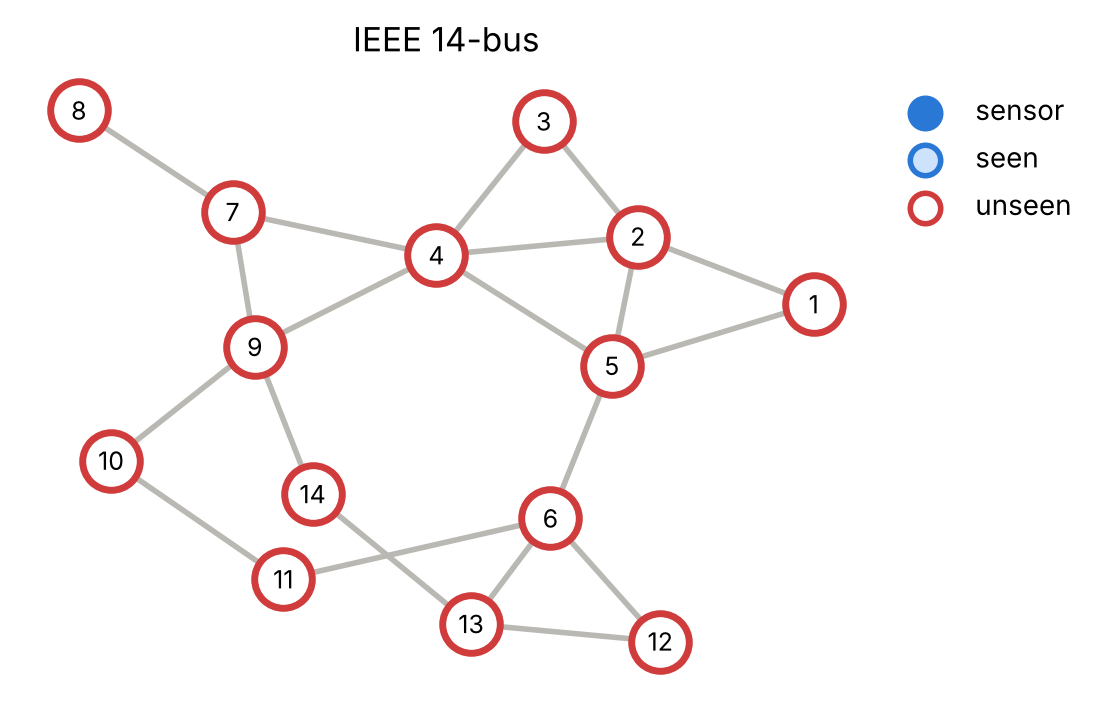

In [2]:
grid = load_grid("data/ieee14.json")
piece = load_grid("data/ieee14_piece6.json")
G = {name: load_grid(f"data/{name}.json") for name in ["ieee14_piece6", "ieee14", "ieee30", "ieee57", "ieee118", "ieee300"]}

def layout(g):
    try:
        import networkx as nx
        return nx.kamada_kawai_layout(nx.Graph(g["lines"]))
    except ImportError:
        a = np.linspace(0, 2 * np.pi, len(g["buses"]), endpoint=False)
        return {b: (np.cos(t), np.sin(t)) for b, t in zip(g["buses"], a)}

pos14 = layout(grid)

def draw_grid(g, chosen=(), title="", pos=None, zib=False, forced=(), cands=(), ax=None):
    pos = pos or layout(g)
    seen = seen_buses(g, chosen, zib)
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(5.5, 4))
    for a, b in g["lines"]:
        ax.plot(*zip(pos[a], pos[b]), color="#b9b8b3", lw=2, zorder=1)
    for b in g["buses"]:
        if b in forced:
            face, ring, txt = "#0d366b", "#0d366b", "white"
        elif b in chosen:
            face, ring, txt = "#2a78d6", "#2a78d6", "white"
        else:
            face = "#cde2fb" if b in seen else "white"
            ring = "#2a78d6" if b in seen else "#d03b3b"
            txt = "black"
        if b in cands:
            ring = "#eb6834"
        ax.scatter(*pos[b], s=430, c=face, edgecolors=ring, linewidths=2.5, zorder=2)
        ax.annotate(str(b), pos[b], ha="center", va="center", fontsize=9, zorder=3, color=txt)
    legend = [("sensor", "#2a78d6", "#2a78d6"), ("seen", "#cde2fb", "#2a78d6"), ("unseen", "white", "#d03b3b")]
    if forced:
        legend.insert(0, ("sensor fixed by rules", "#0d366b", "#0d366b"))
    if cands:
        legend.append(("left for qubits", "white", "#eb6834"))
    for label, face, ring in legend:
        ax.scatter([], [], s=120, c=face, edgecolors=ring, linewidths=2, label=label)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.set_title(title or g["name"])
    ax.margins(0.08); ax.axis("off")
    if own:
        plt.show()

print(grid["name"], len(grid["buses"]), "buses,", len(grid["lines"]), "lines; zero-injection:", grid["zero_injection"])
draw_grid(grid, pos=pos14)

### Milestone 1: placing by hand

Our first hand guess put sensors at the four busiest buses (2, 4, 6, 9). It misses bus 8, which hangs off
bus 7 on a single line. Moving the sensor from 4 to 7 fixes it: {2, 6, 7, 9} sees everything, and section 2
shows 4 is the minimum. That miss is also the first of our reduction rules in section 4. A PMU sees the voltage phasor at its own bus and the current phasors on its lines, and with
known line data that pins down the voltage at each neighboring bus. That is why one PMU sees its neighbors.

The application we design for is **state estimation**: the control room's running estimate of every bus
voltage, which feeds contingency analysis and dispatch. It is used by TVA's transmission operators and
their EMS (energy management system) engineers. NERC's guideline weights it 8 out of 10 in its priority
table (Table 4).

IEEE 14-bus | rules: see neighbors | sensors at [2, 4, 6, 9]
  NOT VALID: buses [8] are unseen (coverage 93%)
IEEE 14-bus | rules: see neighbors | sensors at [2, 6, 7, 9]
  VALID with 4 sensors, redundancy 19
  if the sensor at any of [2, 6, 7, 9] fails, some bus goes unseen


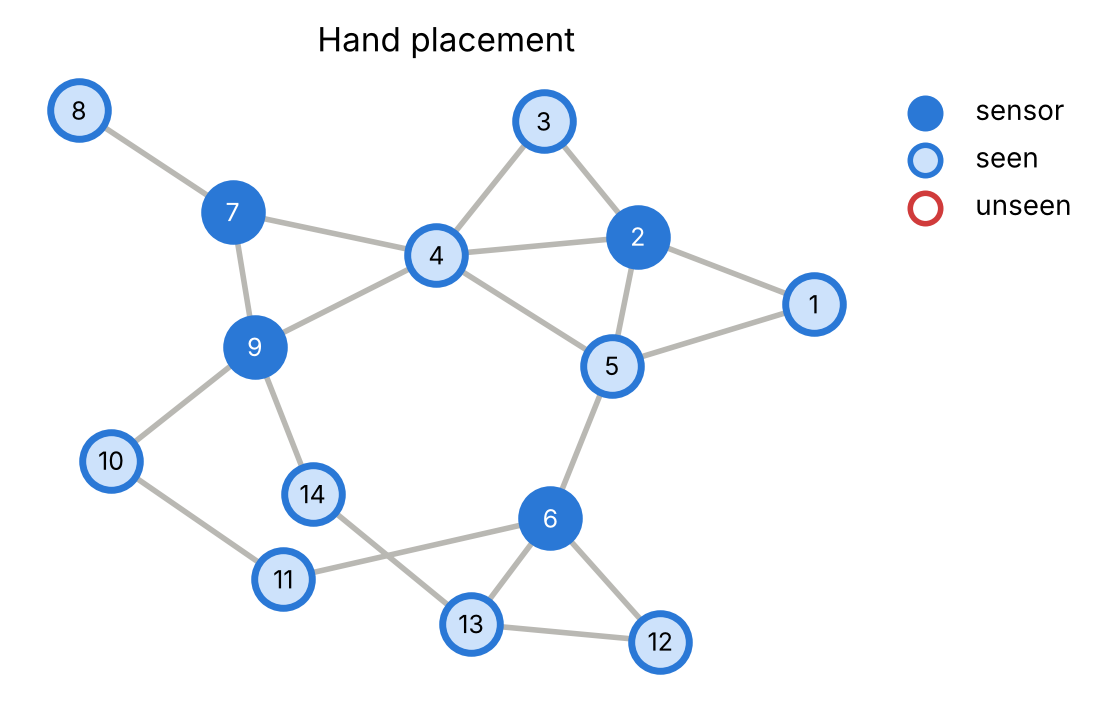

In [3]:
check_placement(grid, [2, 4, 6, 9])   # first try
my_guess = [2, 6, 7, 9]
check_placement(grid, my_guess)
draw_grid(grid, my_guess, "Hand placement", pos=pos14)

## 2. Classical baselines (milestone 2)

* **Greedy:** keep adding the bus that sees the most unseen buses. Fast, not always optimal.
* **ILP (integer linear program):** one 0/1 variable per bus, minimize the count, each bus needs at least one
  sensor nearby. Exact.
* **ZIB ILP:** our own formulation of the zero-injection rule. Each zero-injection bus may be used once to infer
  one bus in its group, and an ordering variable stops circular inferences, so the ILP's answer always
  passes `check_placement(..., zib=True)`.
* **N-1 ILP:** every bus seen twice, so any single PMU can fail.

Times are the best of 5 runs on one CPU core.

In [4]:
def greedy_first(g):
    # the starter's TODO, written out: the greedy rule
    chosen, unseen = [], set(g["buses"])
    while unseen:
        b = max(g["buses"], key=lambda b: len(({b} | g["neighbors"][b]) & unseen))
        chosen.append(b)
        unseen -= {b} | g["neighbors"][b]
    return sorted(chosen)

rows = []
for name, g in G.items():
    gr, tg = timed(greedy_first, g)
    il, ti = timed(ilp_placement, g)
    iz, tz = timed(ilp_placement_zib, g, repeat=3)
    n1, t1 = timed(ilp_placement, g, twice=True)
    assert is_valid(g, gr) and is_valid(g, il) and is_valid(g, iz, zib=True) and is_valid(g, n1, n1=True)
    rows.append((name, len(g["buses"]), len(gr), tg, len(il), ti, len(iz), tz, len(n1), t1))

print(f"{'grid':14s} {'buses':>5s} | {'greedy':>6s} {'ms':>6s} | {'ILP':>4s} {'ms':>6s} | {'ZIB':>4s} {'ms':>6s} | {'N-1':>4s} {'ms':>6s}")
for r in rows:
    print(f"{r[0]:14s} {r[1]:5d} | {r[2]:6d} {r[3]:6.2f} | {r[4]:4d} {r[5]:6.1f} | {r[6]:4d} {r[7]:6.1f} | {r[8]:4d} {r[9]:6.1f}")

grid           buses | greedy     ms |  ILP     ms |  ZIB     ms |  N-1     ms
ieee14_piece6      6 |      2   0.00 |    2    0.8 |    2    0.7 |    5    0.6
ieee14            14 |      5   0.01 |    4    5.9 |    3    4.5 |    9    0.8
ieee30            30 |     10   0.06 |   10    7.5 |    7    5.3 |   21    8.7
ieee57            57 |     18   0.19 |   17   13.9 |   11   48.2 |   33    5.6
ieee118          118 |     36   1.33 |   32    7.6 |   30   17.3 |   68    9.1
ieee300          300 |     96   9.39 |   87   30.1 |   70   55.5 |  202   19.0


IEEE 14-bus | rules: see neighbors | sensors at [2, 7, 11, 13]
  VALID with 4 sensors, redundancy 16
  if the sensor at any of [2, 7, 11, 13] fails, some bus goes unseen
  that is the fewest possible
IEEE 14-bus | rules: see neighbors | sensors at [1, 4, 6, 7, 9]
  VALID with 5 sensors, redundancy 23
  if the sensor at any of [1, 4, 6, 7, 9] fails, some bus goes unseen
  1 more than the fewest possible


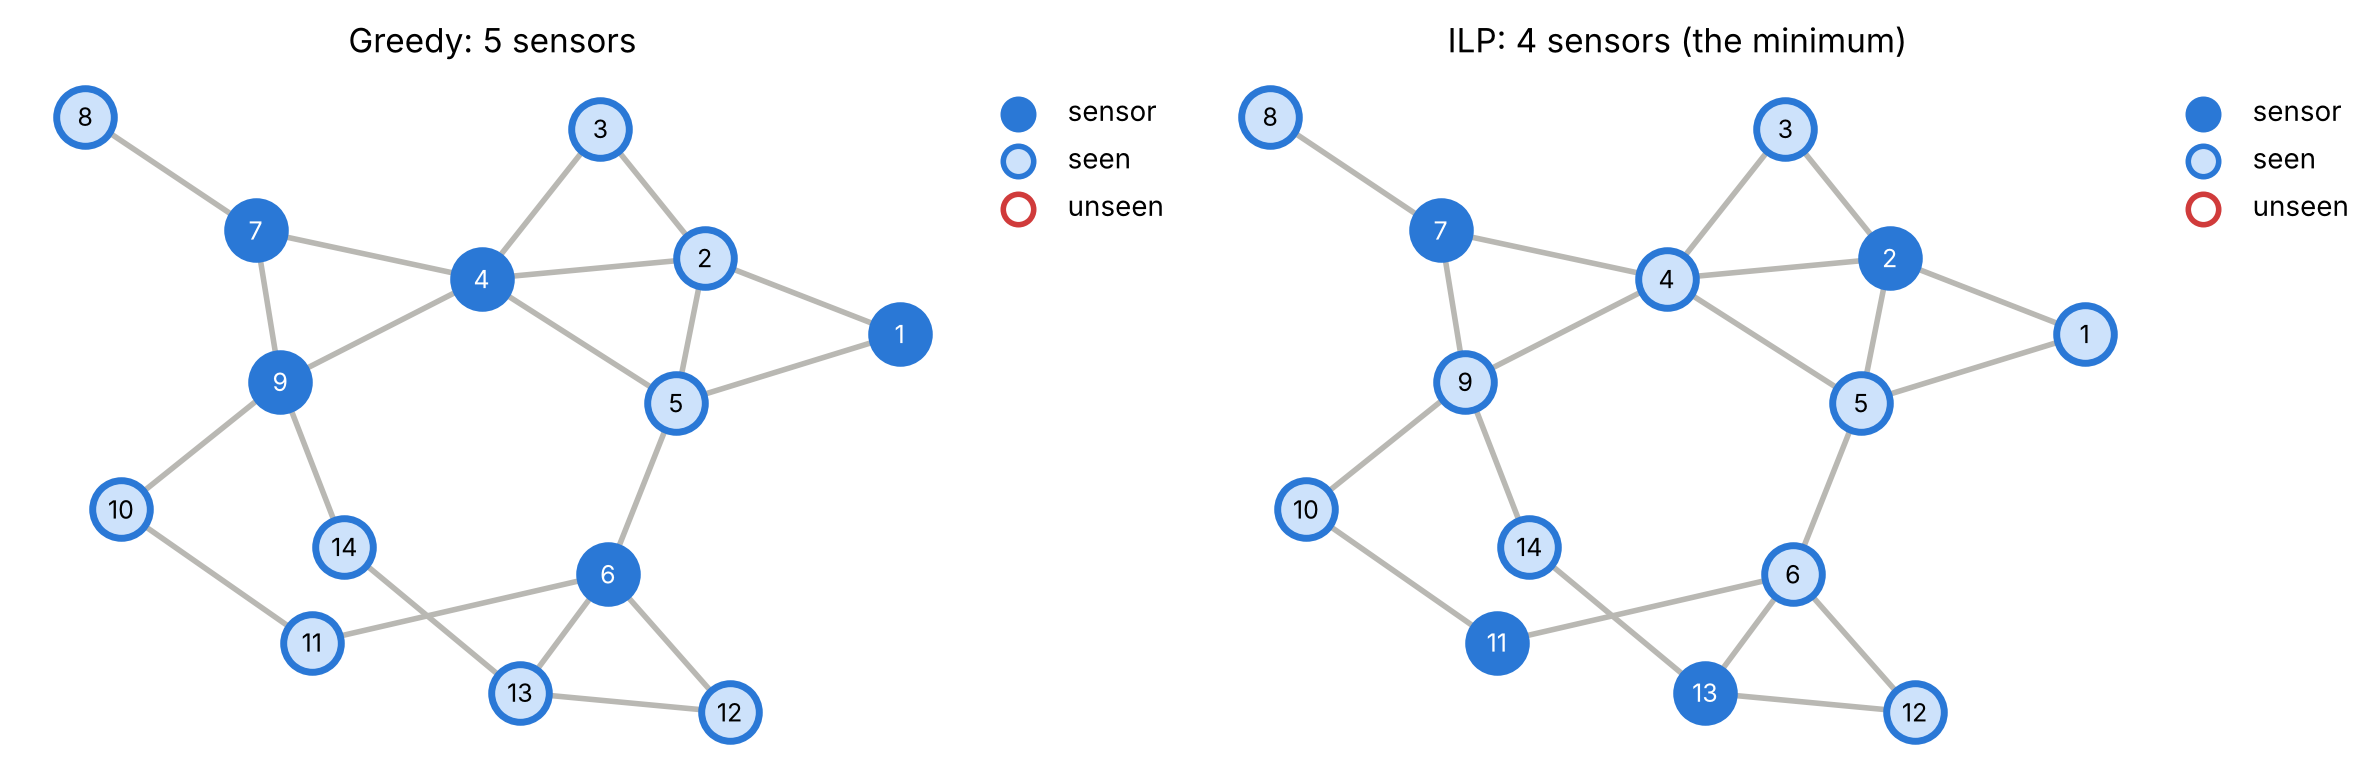

In [5]:
best14 = ilp_placement(grid)
check_placement(grid, best14, compare=True)
check_placement(grid, greedy_first(grid), compare=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw_grid(grid, greedy_first(grid), "Greedy: 5 sensors", pos=pos14, ax=axes[0])
draw_grid(grid, best14, "ILP: 4 sensors (the minimum)", pos=pos14, ax=axes[1])
plt.tight_layout(); plt.show()

Every exact method above finishes in tens of milliseconds, even on 300 buses. So on this problem quantum
has no speed argument to make today. We say that first in our pitch. The rest of this notebook asks a
narrower question: how well does QAOA do, what does it need, and what would have to change.

## 3. The QAOA cost function (milestone 3)

One qubit per bus, $x_b=1$ means "sensor at bus $b$":

$$C(x) = \sum_b x_b + P \sum_b \prod_{j \in N[b]} (1 - x_j), \qquad P = 2$$

The product is 1 only when nothing in bus $b$'s group has a sensor, i.e. bus $b$ is unseen. With $P > 1$,
covering an unseen bus is always cheaper than leaving it, so the cheapest bitstring is an optimal placement.

**How it relates to the primer's Max-Cut:** both are diagonal costs written as phases on bitstrings. Max-Cut
only needs pairs of qubits (one ZZ term per edge). Ours needs a product over a whole group, which becomes a
multi-controlled phase, and that is where the two-qubit gate count blows up.

In [6]:
P = 2.0

def placement_cost(bits, g, P=P):
    # the starter's TODO: sensors + P * unseen buses (bits[i] is qubit i = bus g["buses"][i])
    x = [int(c) for c in bits]
    idx = {b: i for i, b in enumerate(g["buses"])}
    unseen = sum(1 for b in g["buses"] if all(x[idx[j]] == 0 for j in {b} | g["neighbors"][b]))
    return sum(x) + P * unseen

# our vectorized version must agree with the one-string version on every bitstring of the piece
n6 = len(piece["buses"])
fast = cover_cost_table(piece["buses"], grid_constraints(piece), P)
slow = np.array([placement_cost(format(z, f"0{n6}b")[::-1], piece) for z in range(2 ** n6)])
print("cost tables agree:", np.allclose(fast, slow))
z = int(np.argmin(fast))
cheapest = [b for i, b in enumerate(piece["buses"]) if (z >> i) & 1]
print("cheapest bitstring:", cheapest, "| ILP:", ilp_placement(piece))
check_placement(piece, cheapest, compare=True)

# the cost layer (starter's TODO) is qaoa_circuit_cover in pmu_lib: p(-gamma) on each qubit, then
# X / mcp(-gamma*P) / X on each group. Check its statevector against exp(-i*gamma*C) on all 64 strings.
sim = AerSimulator(method="statevector")
params = np.array([0.37, 0.0])  # beta = 0 so only the cost layer acts
qc = qaoa_circuit_cover(piece["buses"], grid_constraints(piece), params, P, measure=False)
qc.save_statevector()
state = np.asarray(sim.run(transpile(qc, sim)).result().get_statevector())
ratio = state / (np.exp(-1j * 0.37 * fast) / np.sqrt(2 ** n6))
print("cost layer matches the cost function:", np.allclose(ratio, ratio[0], atol=1e-6))

cost tables agree: True
cheapest bitstring: [2, 11] | ILP: [2, 11]
IEEE 14-bus, 6-substation piece | rules: see neighbors | sensors at [2, 11]
  VALID with 2 sensors, redundancy 6
  if the sensor at any of [2, 11] fails, some bus goes unseen
  that is the fewest possible
cost layer matches the cost function: True


## 4. Our idea: exact reduction before qubits

Before any qubit is used, we apply three standard covering rules over and over until none applies:

* **R1 (forced):** if only one remaining candidate can see some bus, that sensor must be placed.
* **R2 (bus dominance):** if every candidate that sees bus *u* also sees bus *w*, then seeing *u* already
  guarantees *w*, so *w*'s rule is dropped.
* **R3 (candidate dominance):** if a sensor at *u* would see a subset of what a sensor at *v* sees, then *v*
  is never worse, so *u* stops being a candidate.

None of these can remove every optimal answer, so the best placement of the small leftover problem plus
the forced sensors is a best placement of the whole grid. This is classical, it takes under a
millisecond on IEEE 14, and it is the honest reason our hardware circuit is small.

  R2: whatever sees bus 1 also sees bus 2, so drop bus 2's rule
  R2: whatever sees bus 1 also sees bus 5, so drop bus 5's rule
  R2: whatever sees bus 3 also sees bus 4, so drop bus 4's rule
  R2: whatever sees bus 8 also sees bus 7, so drop bus 7's rule
  R2: whatever sees bus 12 also sees bus 6, so drop bus 6's rule
  R2: whatever sees bus 12 also sees bus 13, so drop bus 13's rule
  R3: a sensor at 2 sees everything 1 would, so drop candidate 1
  R3: a sensor at 2 sees everything 3 would, so drop candidate 3
  R3: a sensor at 2 sees everything 5 would, so drop candidate 5
  R1: bus 1 can only be seen from [2], so put sensors there
  R3: a sensor at 7 sees everything 4 would, so drop candidate 4
  R3: a sensor at 7 sees everything 8 would, so drop candidate 8
  R1: bus 8 can only be seen from [7], so put sensors there
  R3: a sensor at 10 sees everything 11 would, so drop candidate 11
  R3: a sensor at 6 sees everything 12 would, so drop candidate 12
  R3: a sensor at 9 sees everyth

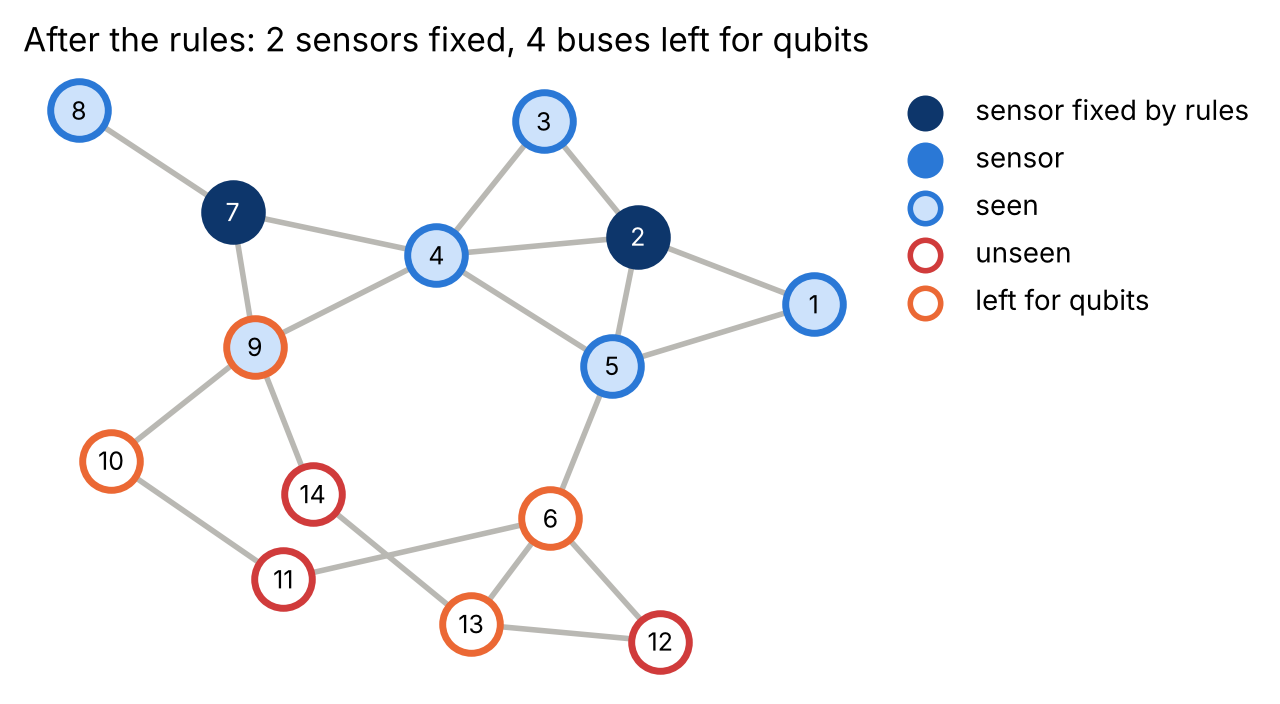

In [7]:
red = reduce_problem(grid, log=True)
print("\nforced sensors:", red["forced"])
print("left for qubits:", red["cands"])
for s, need, buses in red["constraints"]:
    print(f"  bus {buses} must be seen by one of {sorted(s)}")
draw_grid(grid, red["forced"], "After the rules: 2 sensors fixed, 4 buses left for qubits",
          pos=pos14, forced=red["forced"], cands=red["cands"])

What is left is a ring of four pair rules: (9 or 10), (10 or 6), (6 or 13), (13 or 9). Its two best answers
are {6, 9} and {10, 13}, giving full placements {2, 7, 6, 9} and {2, 7, 10, 13}, both 4 sensors. Every
penalty is now a product of two qubits, which is a plain ZZ term, the same shape as Max-Cut.

In [8]:
print(f"{'grid':14s} {'buses':>5s} {'fixed by rules':>15s} {'qubits left':>12s} {'CX/layer full':>14s} {'CX/layer reduced':>17s}")
scale = []
for name, g in G.items():
    r = reduce_problem(g)
    full = cx_count(qaoa_circuit_cover(g["buses"], grid_constraints(g), [0.4, 0.3], measure=False))[0] if len(g["buses"]) <= 118 else None
    kern = cx_count(qaoa_circuit_cover(r["cands"], r["constraints"], [0.4, 0.3], measure=False))[0] if r["cands"] else 0
    pieces = [len(c["cands"]) for c in components(r)]
    sol = r["forced"] + [b for c in components(r) for b in (solve_piece_exact(c["cands"], c["constraints"]) if len(c["cands"]) <= 20 else [])]
    scale.append(dict(grid=name, buses=len(g["buses"]), forced=len(r["forced"]), qubits=len(r["cands"]), cx_full=full, cx_reduced=kern))
    print(f"{name:14s} {len(g['buses']):5d} {len(r['forced']):15d} {len(r['cands']):12d} {str(full):>14s} {kern:17d}")

grid           buses  fixed by rules  qubits left  CX/layer full  CX/layer reduced


ieee14_piece6      6               2            0             26                 0
ieee14            14               2            4            336                 8


ieee30            30              10            0            814                 0


ieee57            57               5           28           1274               286


ieee118          118              13           41           4354               140


ieee300          300              85            3           None                 6


Two things stand out. The rules alone finish IEEE 30 (10 sensors, 0 qubits left), and they leave only
**3 qubits** of IEEE 300 (85 sensors fixed, 87 total). IEEE 57 and 118 keep real cores of 28 and 41 qubits.
So the hard part of this problem lives in a few grids' cores, and that is where any quantum method
would have to earn its place.

## 5. QAOA (milestone 4)

QAOA starts in an equal mix of all placements, then alternates a cost layer (phase $e^{-i\gamma C(x)}$) and
a mixer (`rx(2*beta)` on every qubit). A classical optimizer tunes the angles. We tune on the exact
statevector here (fast for up to 14 qubits) and compare:

* objective: CVaR with alpha = 0.25 (average of the best quarter of shots) versus the plain average (alpha = 1),
* layers 1 to 4,
* three problems: the 6-bus piece, the full IEEE 14 grid, and the reduced IEEE 14 core.

The study takes about a minute: `python qaoa_study.py` reruns it. We load its saved output and replot here.

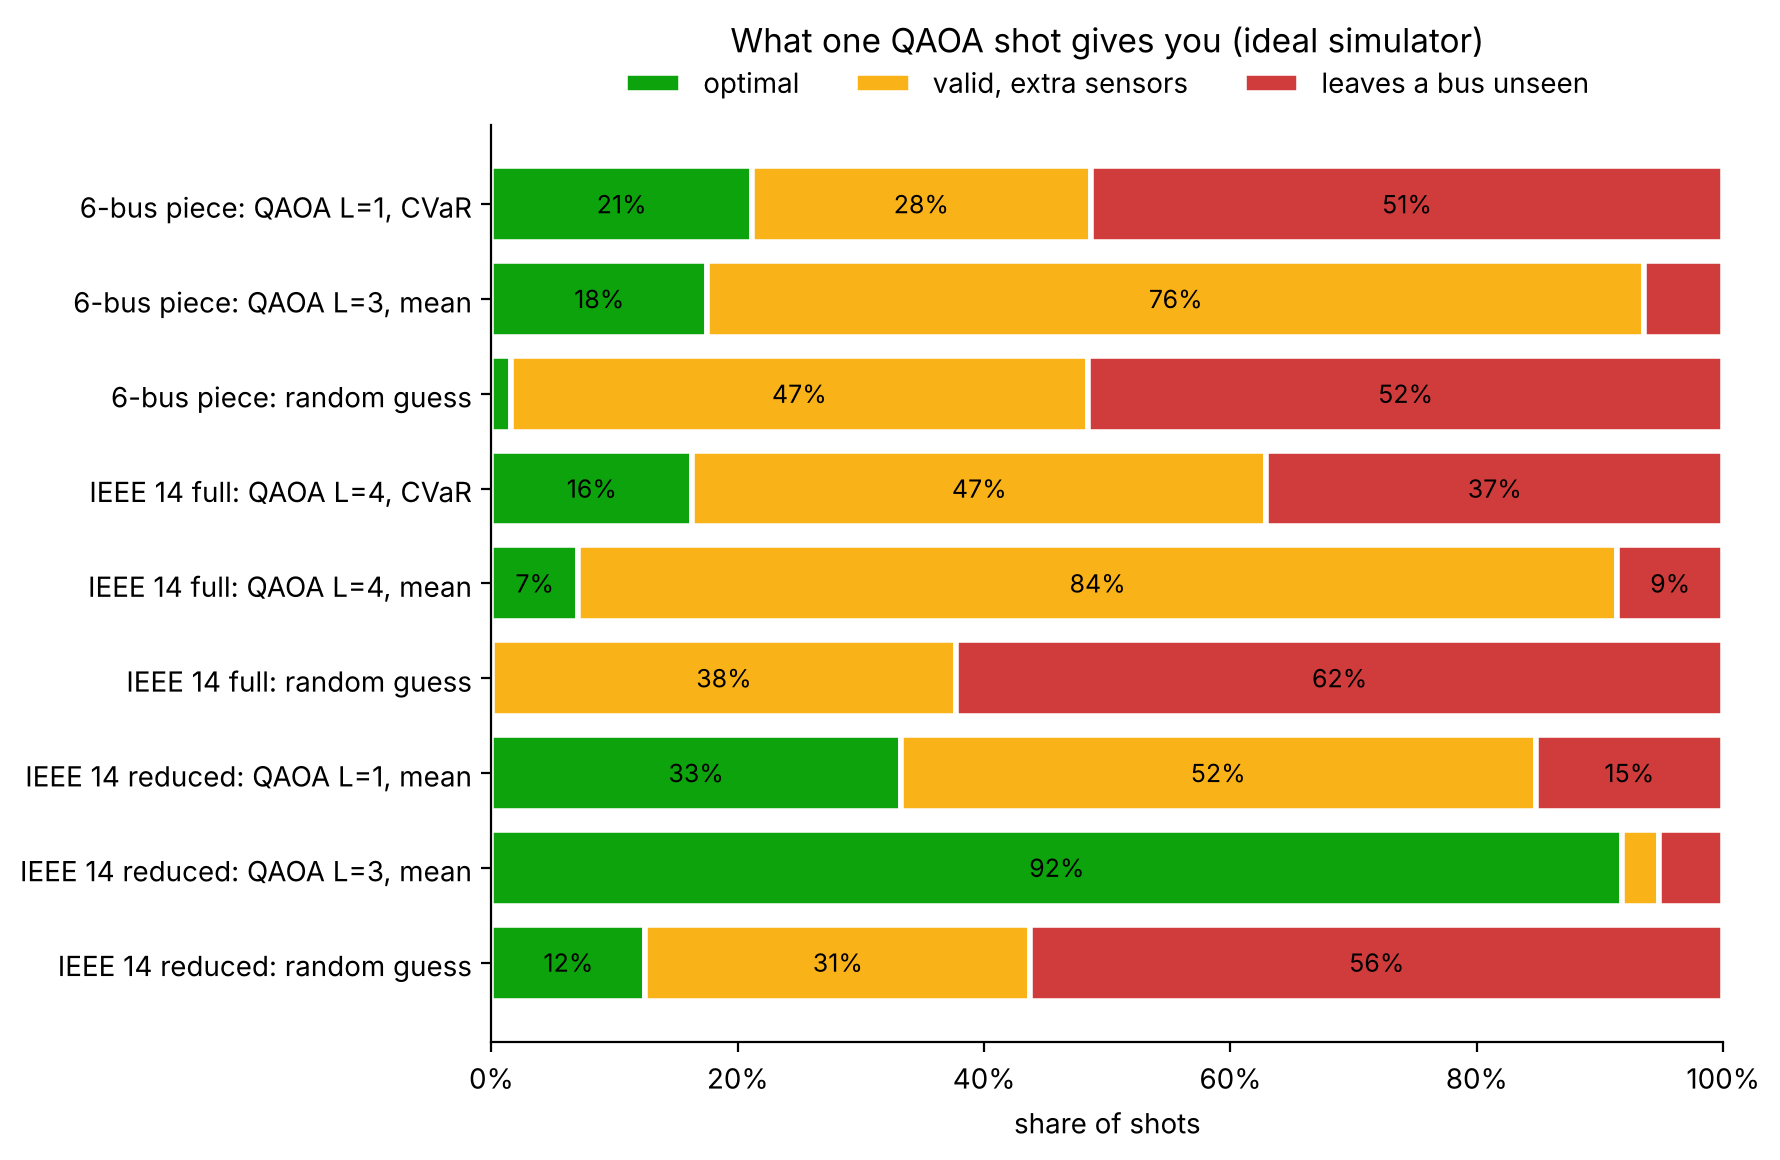

case                         alpha  L  optimal   unseen
6-bus piece (6 qubits)        0.25  1    21.1%    51.3%
6-bus piece (6 qubits)        0.25  2    21.7%    59.3%
6-bus piece (6 qubits)        0.25  3    25.4%    59.5%
6-bus piece (6 qubits)        1.00  1     3.6%    20.8%
6-bus piece (6 qubits)        1.00  2     9.3%     9.1%
6-bus piece (6 qubits)        1.00  3    17.5%     6.4%
IEEE 14 reduced (4 qubits)    0.25  1    26.7%    10.9%
IEEE 14 reduced (4 qubits)    0.25  2    30.9%    45.8%
IEEE 14 reduced (4 qubits)    0.25  3    31.7%    42.7%
IEEE 14 reduced (4 qubits)    1.00  1    33.2%    15.2%
IEEE 14 reduced (4 qubits)    1.00  2    64.7%     9.1%
IEEE 14 reduced (4 qubits)    1.00  3    91.8%     5.2%
IEEE 14 full (14 qubits)      0.25  1     4.4%    55.4%
IEEE 14 full (14 qubits)      0.25  2     6.8%    54.0%
IEEE 14 full (14 qubits)      0.25  3    13.9%    42.5%
IEEE 14 full (14 qubits)      0.25  4    16.3%    37.1%
IEEE 14 full (14 qubits)      1.00  1     2.5%  

In [9]:
import subprocess, sys
if not Path("results/qaoa_study.json").exists():
    subprocess.run([sys.executable, "qaoa_study.py"], check=True)
study = json.load(open("results/qaoa_study.json"))

def pick(case, alpha, L):
    return next(r for r in study if r["case"] == case and r.get("alpha") == alpha and r["layers"] == L)

def rand(case):
    return next(r for r in study if r["case"] == case and r["method"] == "random guess")

def plot_outcomes(rows, title):
    colors = {"optimal": "#0ca30c", "valid, extra sensors": "#fab219", "leaves a bus unseen": "#d03b3b"}
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(rows) + 1.4))
    labels = list(rows)[::-1]
    left = np.zeros(len(labels))
    for kind, color in colors.items():
        vals = np.array([rows[r][kind] for r in labels])
        ax.barh(labels, vals, left=left, color=color, edgecolor="white", linewidth=2, label=kind)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v > 0.07:
                ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=9)
        left += vals
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of shots"); ax.set_title(title, pad=26)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout(); plt.show()

P6, F14, R14 = "6-bus piece (6 qubits)", "IEEE 14 full (14 qubits)", "IEEE 14 reduced (4 qubits)"
plot_outcomes({
    "6-bus piece: QAOA L=1, CVaR": pick(P6, 0.25, 1),
    "6-bus piece: QAOA L=3, mean": pick(P6, 1.0, 3),
    "6-bus piece: random guess": rand(P6),
    "IEEE 14 full: QAOA L=4, CVaR": pick(F14, 0.25, 4),
    "IEEE 14 full: QAOA L=4, mean": pick(F14, 1.0, 4),
    "IEEE 14 full: random guess": rand(F14),
    "IEEE 14 reduced: QAOA L=1, mean": pick(R14, 1.0, 1),
    "IEEE 14 reduced: QAOA L=3, mean": pick(R14, 1.0, 3),
    "IEEE 14 reduced: random guess": rand(R14),
}, "What one QAOA shot gives you (ideal simulator)")

print(f"{'case':28s} {'alpha':>5s} {'L':>2s} {'optimal':>8s} {'unseen':>8s}")
for r in study:
    if r["method"] == "QAOA":
        print(f"{r['case']:28s} {r['alpha']:5.2f} {r['layers']:2d} {r['optimal']:8.1%} {r['leaves a bus unseen']:8.1%}")

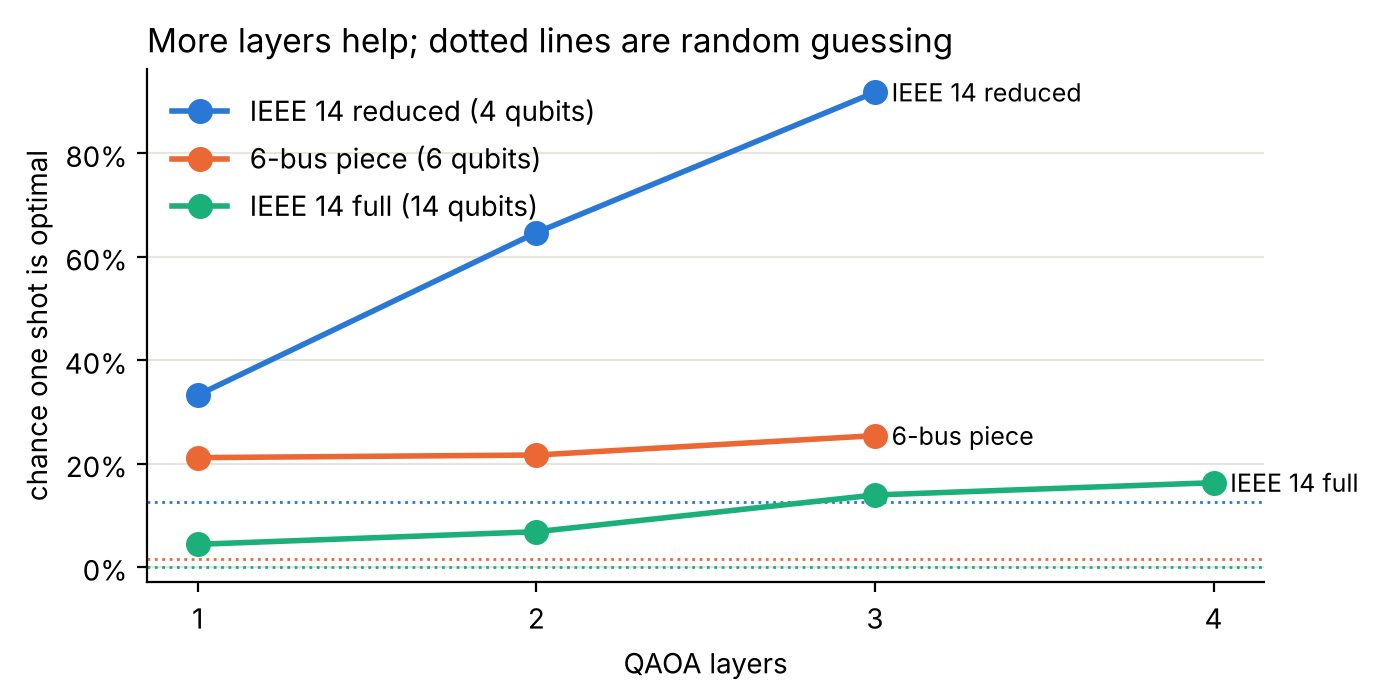

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for case, color, a in [(R14, "#2a78d6", 1.0), (P6, "#eb6834", 0.25), (F14, "#1baf7a", 0.25)]:
    Ls = sorted({r["layers"] for r in study if r["case"] == case and r["method"] == "QAOA"})
    ys = [pick(case, a, L)["optimal"] for L in Ls]
    ax.plot(Ls, ys, "-o", color=color, lw=2, ms=8, label=f"{case}")
    ax.axhline(rand(case)["optimal"], color=color, lw=1, ls=":")
    ax.annotate(case.split(" (")[0], (Ls[-1], ys[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlabel("QAOA layers"); ax.set_ylabel("chance one shot is optimal")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("More layers help; dotted lines are random guessing", loc="left")
ax.legend(frameon=False, loc="upper left"); ax.set_xticks([1, 2, 3, 4])
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="y", color="#e6e5e0"); plt.tight_layout(); plt.show()

**What this says.** On the full 14-bus grid, a random placement is optimal 0.03% of the time (5 of 16,384).
QAOA with 4 layers gets 16% per shot, about 500 times better than guessing, but its circuit is over 1,300
two-qubit gates. The reduced core reaches 92% optimal with 3 layers and 24 two-qubit gates. The
6-bus piece behaves like the README warned: CVaR finds the optimum about 1 in 5 shots but leaves a bus
unseen half the time, because it only rewards the best quarter of shots.

**Caveat we say out loud:** the tuning above computed the cost of every bitstring first, so the classical
side already knew the answer. Section 7 tunes from shots instead.

## 6. Noise

Our own rough noise model: depolarizing error on every two-qubit gate (swept from 0 to 5%), one twentieth
of that on one-qubit gates, and the same rate of readout flips. Published two-qubit fidelity for Forte
ranges from about 99.3% (median randomized benchmarking, arXiv 2603.15515) to 99.6% (IonQ), so the 0.5%
column is our middle guess for Forte. (This is not IonQ's `forte-1` noise
model; that one runs on IonQ's simulator through qBraid in section 10.) `python noise_study.py` reruns it.

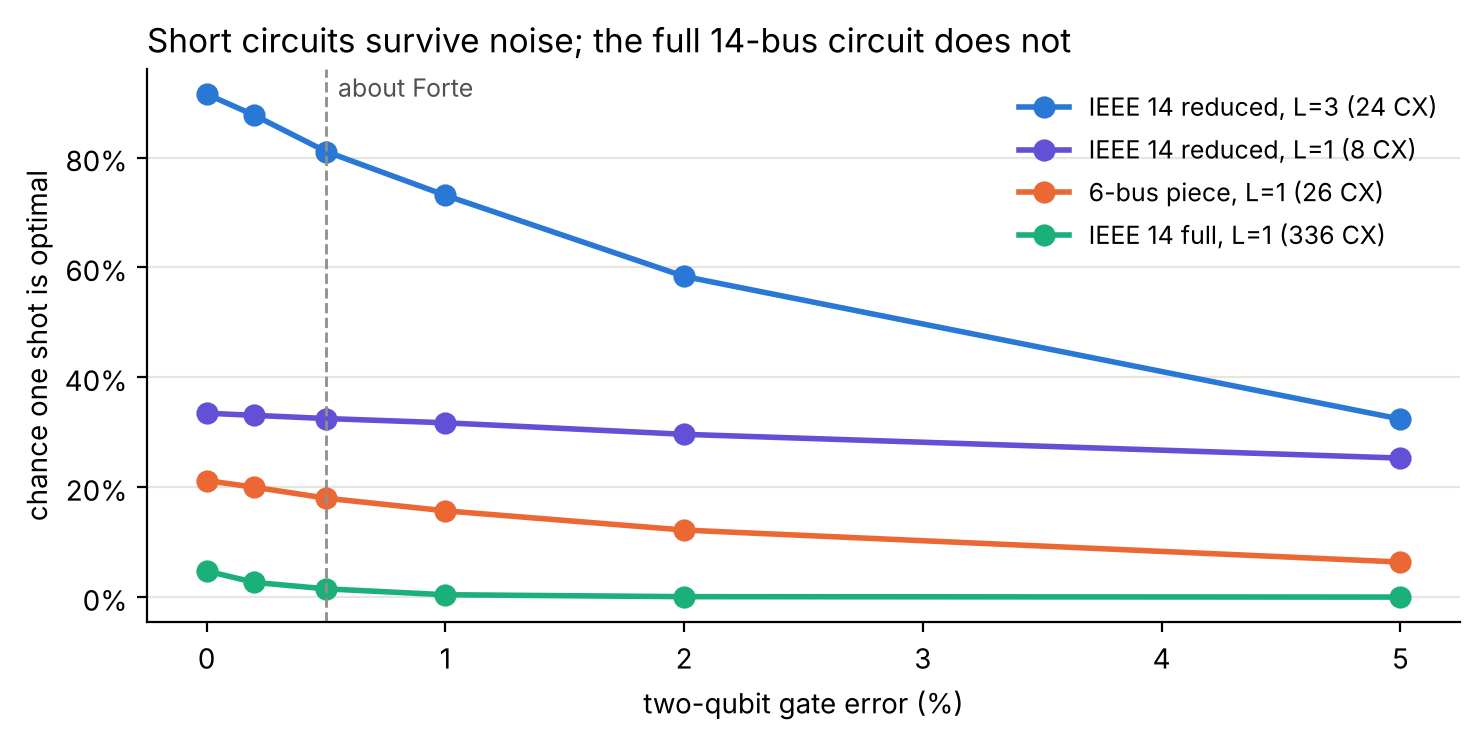

at 0.5% error: 6-bus piece, L=1       optimal 18.0%, unseen 52.5%
at 0.5% error: IEEE 14 reduced, L=1   optimal 32.5%, unseen 16.9%
at 0.5% error: IEEE 14 reduced, L=3   optimal 81.1%, unseen 11.1%
at 0.5% error: IEEE 14 full, L=1      optimal 1.5%, unseen 60.0%


In [11]:
if not Path("results/noise_study.json").exists():
    subprocess.run([sys.executable, "noise_study.py"], check=True)
noise = json.load(open("results/noise_study.json"))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = {"IEEE 14 reduced, L=3": "#2a78d6", "IEEE 14 reduced, L=1": "#6250d6", "6-bus piece, L=1": "#eb6834", "IEEE 14 full, L=1": "#1baf7a"}
for case, color in colors.items():
    pts = [(r["p2"], r["optimal"], r["cx"]) for r in noise if r["case"] == case]
    xs, ys, cx = zip(*pts)
    ax.plot(np.array(xs) * 100, ys, "-o", color=color, lw=2, ms=7, label=f"{case} ({cx[0]} CX)")
ax.axvline(0.5, color="#8f8e88", lw=1, ls="--"); ax.text(0.55, 0.95, "about Forte", fontsize=9, color="#52514e", transform=ax.get_xaxis_transform())
ax.set_xlabel("two-qubit gate error (%)"); ax.set_ylabel("chance one shot is optimal")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Short circuits survive noise; the full 14-bus circuit does not", loc="left")
ax.legend(frameon=False, loc="upper right", fontsize=9)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="y", color="#e6e5e0"); plt.tight_layout(); plt.show()
for r in noise:
    if r["p2"] == 0.005:
        print(f"at 0.5% error: {r['case']:22s} optimal {r['optimal']:.1%}, unseen {r['leaves a bus unseen']:.1%}")

## 7. Tuning from shots only

At real scale nobody can list all $2^n$ costs. So here the optimizer only sees sampled shots: each
evaluation runs the circuit 256 times on Aer, scores just those bitstrings with the checker, and averages
the cheapest share. `python shot_tuning.py` reruns it.

In [12]:
if not Path("results/shot_tuning.json").exists():
    subprocess.run([sys.executable, "shot_tuning.py"], check=True)
for r in json.load(open("results/shot_tuning.json")):
    exact = pick(r["case"], 1.0 if "reduced" in r["case"] else 0.25, r["layers"])["optimal"]
    print(f"{r['case']:28s} L={r['layers']}: {r['shots_used_for_tuning']:6d} tuning shots -> optimal {r['optimal']:.1%} "
          f"(exact-table tuning got {exact:.1%})")

IEEE 14 reduced (4 qubits)   L=3:  43008 tuning shots -> optimal 67.9% (exact-table tuning got 91.8%)
6-bus piece (6 qubits)       L=1:  15104 tuning shots -> optimal 3.6% (exact-table tuning got 21.1%)
IEEE 14 full (14 qubits)     L=2:  29952 tuning shots -> optimal 0.8% (exact-table tuning got 6.8%)


Tuning from shots works, but it costs 15,000 to 45,000 shots and lands on worse angles than the exact
table. On hardware that is the expensive part: the README's AWS price is about 1,630 credits per 200 Forte
shots, so 30,000 tuning shots would be roughly 150 such jobs. That is a real cost quantum pays that the
ILP does not.

## 8. Stretch goals

### Zero-injection buses
Bus 7 has no load and no generator, so the current into it sums to zero. If all but one bus in its group
is seen, the last one follows. That drops IEEE 14 from 4 sensors to 3.

IEEE 14-bus | rules: see neighbors + zero-injection rule | sensors at [2, 6, 9]
  VALID with 3 sensors, redundancy 15
  if the sensor at any of [2, 6, 9] fails, some bus goes unseen
  that is the fewest possible


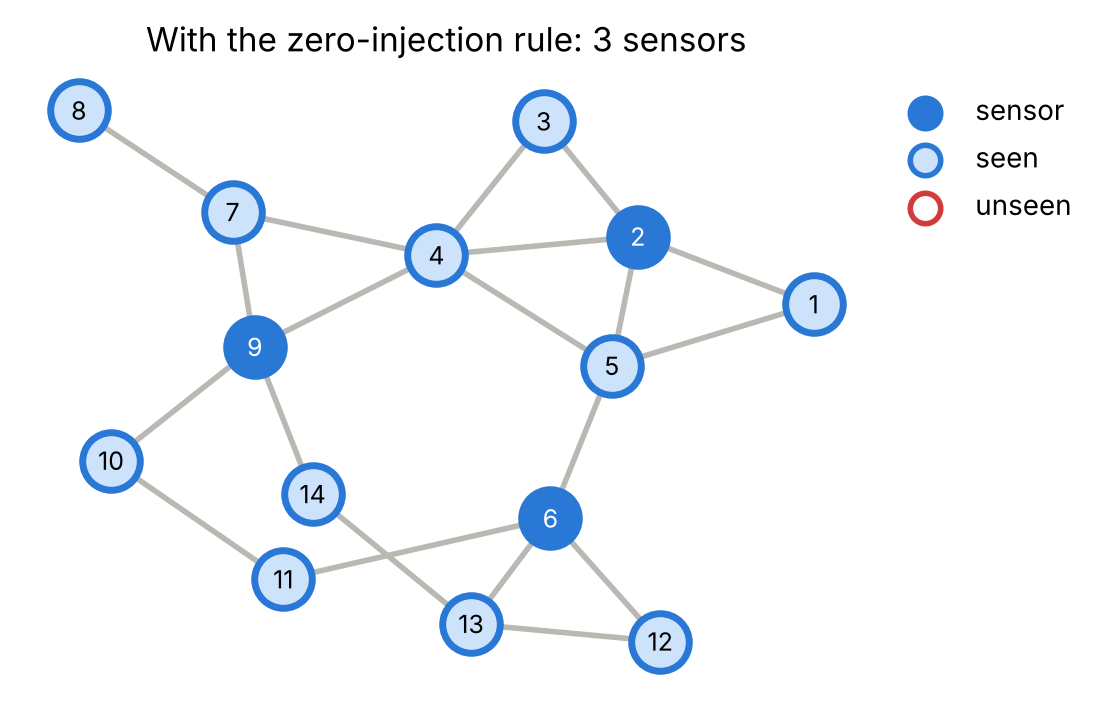

In [13]:
zib14 = ilp_placement_zib(grid)
check_placement(grid, zib14, zib=True, compare=True)
draw_grid(grid, zib14, "With the zero-injection rule: 3 sensors", pos=pos14, zib=True)

### N-1: survive any one PMU failure
Plain N-1 needs 9 sensors on IEEE 14. With the zero-injection rule it is 7 (brute force agrees).
Robustness costs 3 to 5 extra PMUs, which at DOE's installed cost is real money: the trade-off TVA
actually decides.

For N-1 with zero-injection we wrote an exact ILP that adds failure scenarios one at a time: one shared
set of sensors, plus a copy of the zero-injection block for each sensor whose loss we must survive. Only
scenarios that actually break the current answer get added. It solves IEEE 30 in 0.3 s (our first
no-good-cut version took 47 s) and IEEE 300 in about 14 minutes.

IEEE 14-bus | rules: see neighbors + N-1 | sensors at [2, 4, 5, 6, 7, 8, 9, 11, 13]
  VALID with 9 sensors, redundancy 39
  survives any single sensor failure
  that is the fewest possible


IEEE 14-bus | rules: see neighbors + zero-injection rule + N-1 | sensors at [1, 2, 4, 6, 9, 10, 13]
  VALID with 7 sensors, redundancy 31
  survives any single sensor failure
  that is the fewest possible


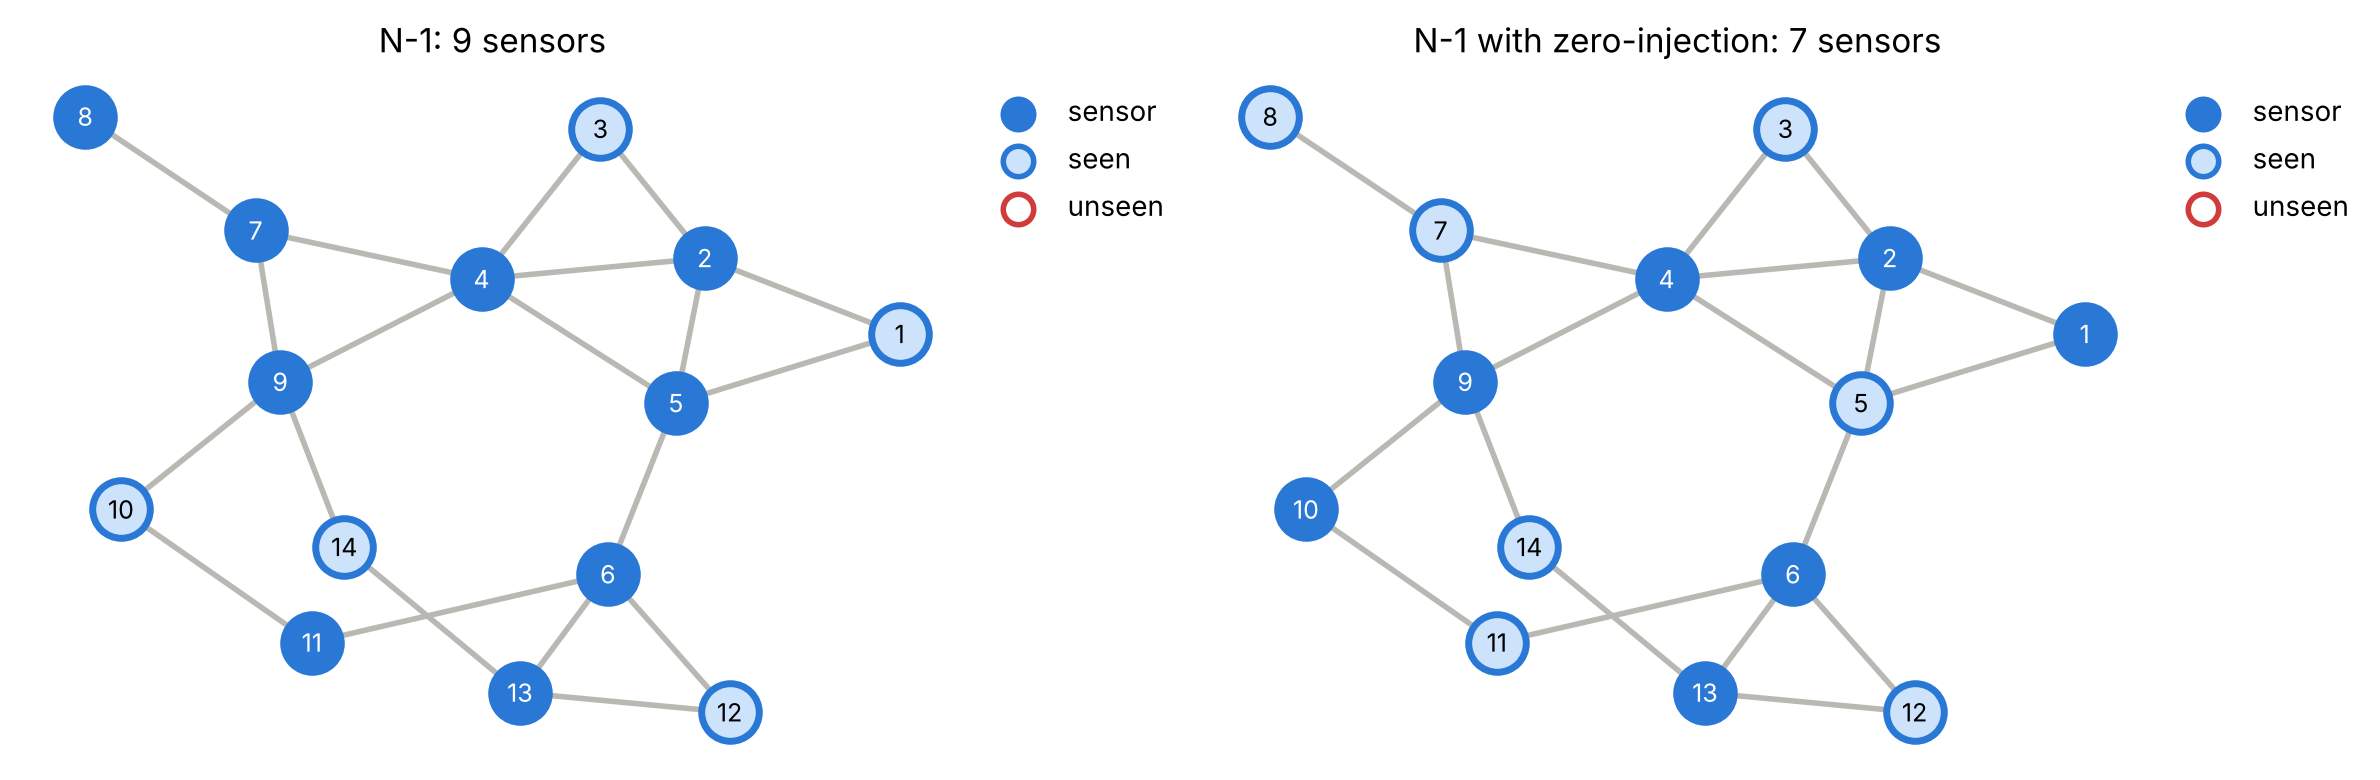

lose the PMU at bus  2: unseen [1, 2, 3, 5]
lose the PMU at bus  7: unseen [7, 8, 9]
lose the PMU at bus 11: unseen [10, 11]
lose the PMU at bus 13: unseen [12, 13, 14]


In [14]:
n1 = ilp_placement(grid, twice=True)
check_placement(grid, n1, n1=True, compare=True)
n1z = ilp_n1_zib_scenarios(grid)
check_placement(grid, n1z, zib=True, n1=True, compare=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw_grid(grid, n1, "N-1: 9 sensors", pos=pos14, ax=axes[0])
draw_grid(grid, n1z, "N-1 with zero-injection: 7 sensors", pos=pos14, zib=True, ax=axes[1])
plt.tight_layout(); plt.show()

# what fails in the 4-sensor optimum if one PMU drops out?
for lost in best14:
    left = [b for b in best14 if b != lost]
    print(f"lose the PMU at bus {lost:2d}: unseen {sorted(set(grid['buses']) - seen_buses(grid, left))}")

### Fixed budget with NERC-style priority weights

NERC's Table 4 scores each location by the applications a PMU there would serve, with a 10-point weight
per application. We built the same table for IEEE 14. **Our assumptions** (label them as such): the
transformers 4-7, 4-9 and 5-6 join the high- and low-voltage areas, so their end buses serve angle
monitoring; generator buses (1, 2, 3, 6, 8) serve oscillation monitoring and model verification; buses 1
and 2 make real power, so they serve frequency response; loads of 20 MW or more serve disturbance
monitoring; every bus serves state estimation.

With only *k* sensors we maximize the total weight of the buses seen. On the quantum side, a standard
penalty for "use exactly k sensors" wastes about half the shots on the wrong count. We instead start in an
equal mix of all k-sensor placements and use an **XY mixer** that only moves sensors around, so every
single shot has exactly k sensors. (Simulated in the k-sensor subspace; on hardware the start state and
mixer need extra gates.) `python stretch_study.py` reruns this.

In [15]:
if not Path("results/stretch_study.json").exists():
    subprocess.run([sys.executable, "stretch_study.py"], check=True)
st = json.load(open("results/stretch_study.json"))
apps = st["priority_table"]["apps"]; w = {int(k): v for k, v in st["priority_table"]["weights"].items()}
print(f"{'bus':>4s} " + " ".join(f"{a[:10]:>10s}" for a in apps) + f" {'score':>6s}")
for b in grid["buses"]:
    print(f"{b:4d} " + " ".join(f"{(1 if b in s else 0):>10d}" for _, s in apps.values()) + f" {w[b]:6d}")
print("weights:", " ".join(f"{a}={v[0]}" for a, v in apps.items()))
print()
for r in st["budget_ilp"]:
    print(f"k={r['k']}: weighted best {r['weighted']} (score {r['weighted_score']}/{r['max_score']}, sees {r['buses_seen_weighted']} buses); "
          f"count-only best {r['unweighted']} (score {r['unweighted_score_w']}, sees {r['buses_seen_unweighted']} buses)")
print()
for r in st["budget"]:
    extra = f", exactly k sensors {r['p_exactly_k']:.0%}" if "p_exactly_k" in r else ""
    print(f"k={r['k']} {r['method']:18s} L={r.get('layers', '-')}: optimal {r['p_optimal']:.1%}{extra}")

 bus State esti Oscillatio Angle moni Model veri Disturbanc Frequency   score
   1          1          1          0          1          0          1     33
   2          1          1          0          1          1          1     43
   3          1          1          0          1          1          0     38
   4          1          0          1          0          1          0     26
   5          1          0          1          0          0          0     16
   6          1          1          1          1          0          0     36
   7          1          0          1          0          0          0     16
   8          1          1          0          1          0          0     28
   9          1          0          1          0          1          0     26
  10          1          0          0          0          0          0      8
  11          1          0          0          0          0          0      8
  12          1          0          0          0          0     

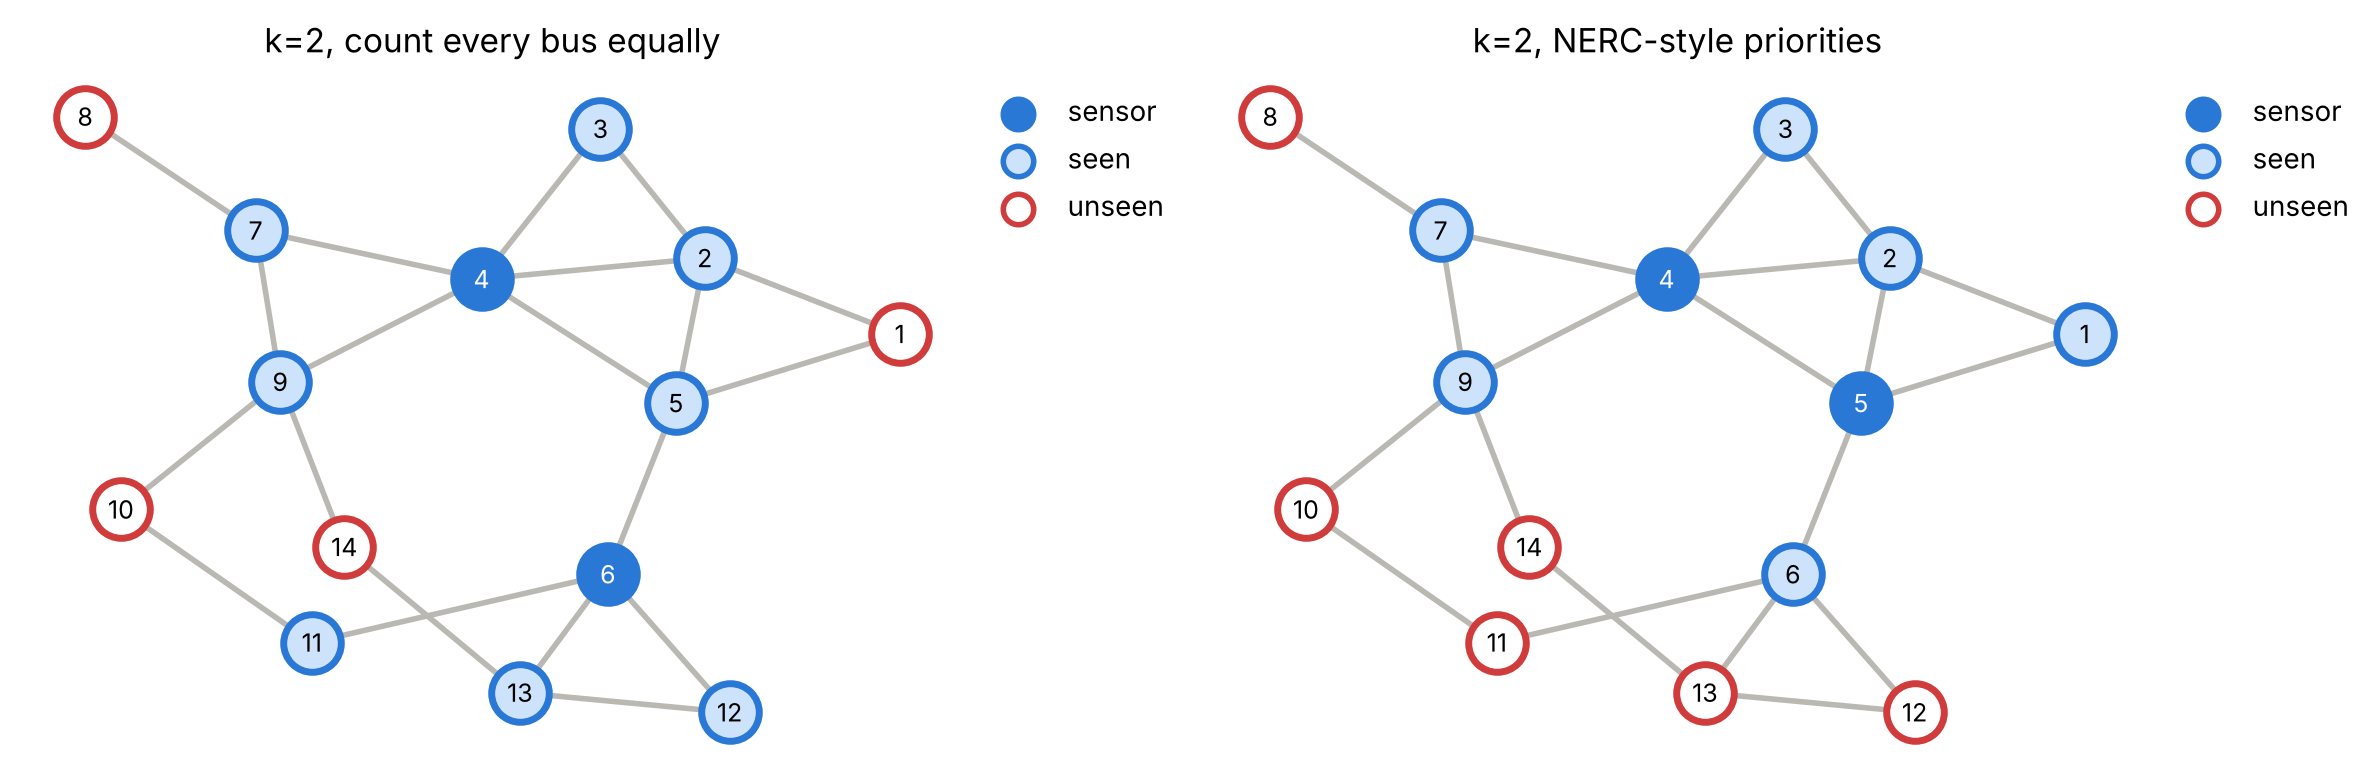

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
draw_grid(grid, st["budget_ilp"][0]["unweighted"], "k=2, count every bus equally", pos=pos14, ax=axes[0])
draw_grid(grid, st["budget_ilp"][0]["weighted"], "k=2, NERC-style priorities", pos=pos14, ax=axes[1])
plt.tight_layout(); plt.show()

With 2 sensors, the priorities move one PMU from bus 6 to bus 5: the weighted plan sees fewer low-weight
buses but covers both transformer ends and more of the generators. For QAOA, the XY mixer finds the
weighted optimum 25% of the time at k = 2 (random: 1.1%), while the penalty version manages under 1%.
At k = 3 the XY mixer is weaker (3.2% vs 0.55% random), which we report as is.

N-1 and zero-injection with QAOA (simulation only):

In [17]:
print(f"N-1 core after the rules: {st['n1']['qubits']} qubits, {len(st['n1']['forced'])} sensors fixed, best total {st['n1']['best']}")
for r in st["n1"]["runs"]:
    print(f"  L={r['layers']}: optimal {r['p_optimal']:.1%}, valid {r['p_valid']:.1%}  (random optimal {st['n1']['random_p_optimal']:.2%})")
print("Zero-injection on all 14 qubits (cost needs the propagation rule, so no short circuit):")
for r in st["zib"]["runs"]:
    print(f"  L={r['layers']}: optimal {r['p_optimal']:.2%}, valid {r['p_valid']:.1%}  (random optimal {st['zib']['random_p_optimal']:.3%})")

N-1 core after the rules: 12 qubits, 2 sensors fixed, best total 9
  L=1: optimal 1.5%, valid 38.0%  (random optimal 0.20%)
  L=2: optimal 7.7%, valid 46.9%  (random optimal 0.20%)
  L=3: optimal 12.6%, valid 59.5%  (random optimal 0.20%)
Zero-injection on all 14 qubits (cost needs the propagation rule, so no short circuit):
  L=1: optimal 2.56%, valid 35.7%  (random optimal 0.006%)
  L=2: optimal 3.45%, valid 42.1%  (random optimal 0.006%)
  L=3: optimal 3.76%, valid 64.9%  (random optimal 0.006%)


### A second quantum method: Grover search on the core

QAOA needs a classical optimizer to tune its angles, which cost us 15,000 to 45,000 shots in section 7.
Grover search needs no tuning. The question "does this placement see every bus with at most k sensors?"
is a yes/no check, so we write it as a boolean formula (one OR clause per bus, plus "no k+1 sensors
together"), let Qiskit synthesize it into a phase oracle, and amplify the placements that pass. We lower k
until nothing passes (Grover adaptive search over the budget).

One caveat we state: we pick the number of Grover steps from the count of marked placements, which we
computed on the tiny core. Without that count you would use the randomized schedule of Boyer, Brassard,
Hoyer and Tapp, which costs a few more runs. `python grover_study.py` reruns this.

In [18]:
if not Path("results/grover_study.json").exists():
    subprocess.run([sys.executable, "grover_study.py"], check=True)
gro = json.load(open("results/grover_study.json"))
print(f"{'core':14s} {'k (total)':>10s} {'marked':>6s} {'steps':>5s} {'CX':>4s} {'optimal ideal':>14s} {'at 0.5% error':>14s}")
for r in gro:
    print(f"{r['case']:14s} {r['k_core']:>3d} ({r['k_total']:>3d}) {r['marked']:>6d} {r['iterations']:>5d} {r['cx']:>4d} "
          f"{r['optimal@0.0']:>14.0%} {r['optimal@0.005']:>14.0%}")
print()
print(cover_expression(red["cands"], red["constraints"], 2), "   (q0..q3 = buses", red["cands"], ")")

core            k (total) marked steps   CX  optimal ideal  at 0.5% error
IEEE 14 core     4 (  6)      7     1   34            20%            18%
IEEE 14 core     3 (  5)      6     1   52            29%            24%
IEEE 14 core     2 (  4)      2     2   84            94%            67%
IEEE 300 core    3 ( 88)      4     0    0            37%            38%
IEEE 300 core    2 ( 87)      3     1   24            84%            78%

(q1 | q2) & (q0 | q2) & (q0 | q3) & (q1 | q3) & ~(q0 & q1 & q2) & ~(q0 & q1 & q3) & ~(q0 & q2 & q3) & ~(q1 & q2 & q3)    (q0..q3 = buses [6, 9, 10, 13] )


On the IEEE 14 core with k = 2, two Grover steps mark the 2 optimal placements out of 16 and hit one 94%
of the time, with 84 two-qubit gates and zero tuning shots. QAOA with 3 layers reaches 92% with 24 gates but
needed its angles tuned first. So the trade is gates for tuning: Grover is cleaner when the core is small
enough that its oracle is cheap, QAOA when gates are the bottleneck. On the IEEE 300 core, one Grover step
(24 CX) finds the optimum 84% of the time.

## 9. Bigger grids

The integer program solves IEEE 300 in about 30 ms. After our rules, the cores QAOA would need are:
IEEE 57: 28 qubits, 286 CX per layer. IEEE 118: 41 qubits, 140 CX per layer. IEEE 300: 3 qubits. So
IEEE 118's core is past Forte's 36 qubits, and IEEE 57's core is past the few-dozen-gate depth that runs well
today. The 300-bus core is tiny, and we include it in the hardware runs to make that point concretely.

In [19]:
g300 = G["ieee300"]
red300 = reduce_problem(g300)
print("IEEE 300 core:", red300["cands"], [(sorted(s), u) for s, _, u in red300["constraints"]])
cost300 = cover_cost_table(red300["cands"], red300["constraints"])
params300, probs300 = run_qaoa(cost300, len(red300["cands"]), layers=1, alpha=1.0)
sh300 = shares(red300["cands"], red300["constraints"], probs300, 87, len(red300["forced"]))
print("QAOA L=1 on the 300-bus core:", {k: f"{v:.1%}" for k, v in sh300.items()})

IEEE 300 core: [243, 245, 246] [([243, 245], [243]), ([243, 246], [244]), ([245, 246], [247])]


QAOA L=1 on the 300-bus core: {'optimal': '72.0%', 'valid, extra sensors': '8.2%', 'leaves a bus unseen': '19.8%'}


### IEEE 300: every stretch goal

Classical, all exact: minimum, zero-injection, N-1, N-1 with zero-injection, and the fixed-budget curve
with NERC-style weights. Our weights for IEEE 300 (no transformer data, so no angle-monitoring row): every
bus 8 for state estimation; generator buses another 25 (oscillation 10, model verification 10, frequency
response 5); buses with 100 MW of load or more another 10 (disturbance monitoring).

Quantum: **QAOA window search.** Start from the greedy answer. Free a window of up to 10 neighboring buses
(8 with zero-injection) while every other sensor stays put, let QAOA propose a cheaper set for the window
from 200 shots, and keep it only if the checker says the whole grid is still covered. Every window is a
small circuit, so this is how QAOA could work on a 300-bus grid with today's hardware. The baseline gets
the same 200 shots per window but samples them at random. `python ieee300_study.py` reruns it.

IEEE 300, exact classical answers
  Greedy                   96 PMUs       22 ms
  ILP                      87 PMUs       40 ms
  ILP + zero-injection     70 PMUs       80 ms
  Greedy N-1              209 PMUs       42 ms
  N-1 ILP                 202 PMUs       28 ms
  N-1 + zero-injection    159 PMUs   843700 ms   (scenario ILP; valid: True)

N-1 with zero-injection on every grid: {'ieee14': 7, 'ieee30': 14, 'ieee57': 23, 'ieee118': 63, 'ieee300': 159}


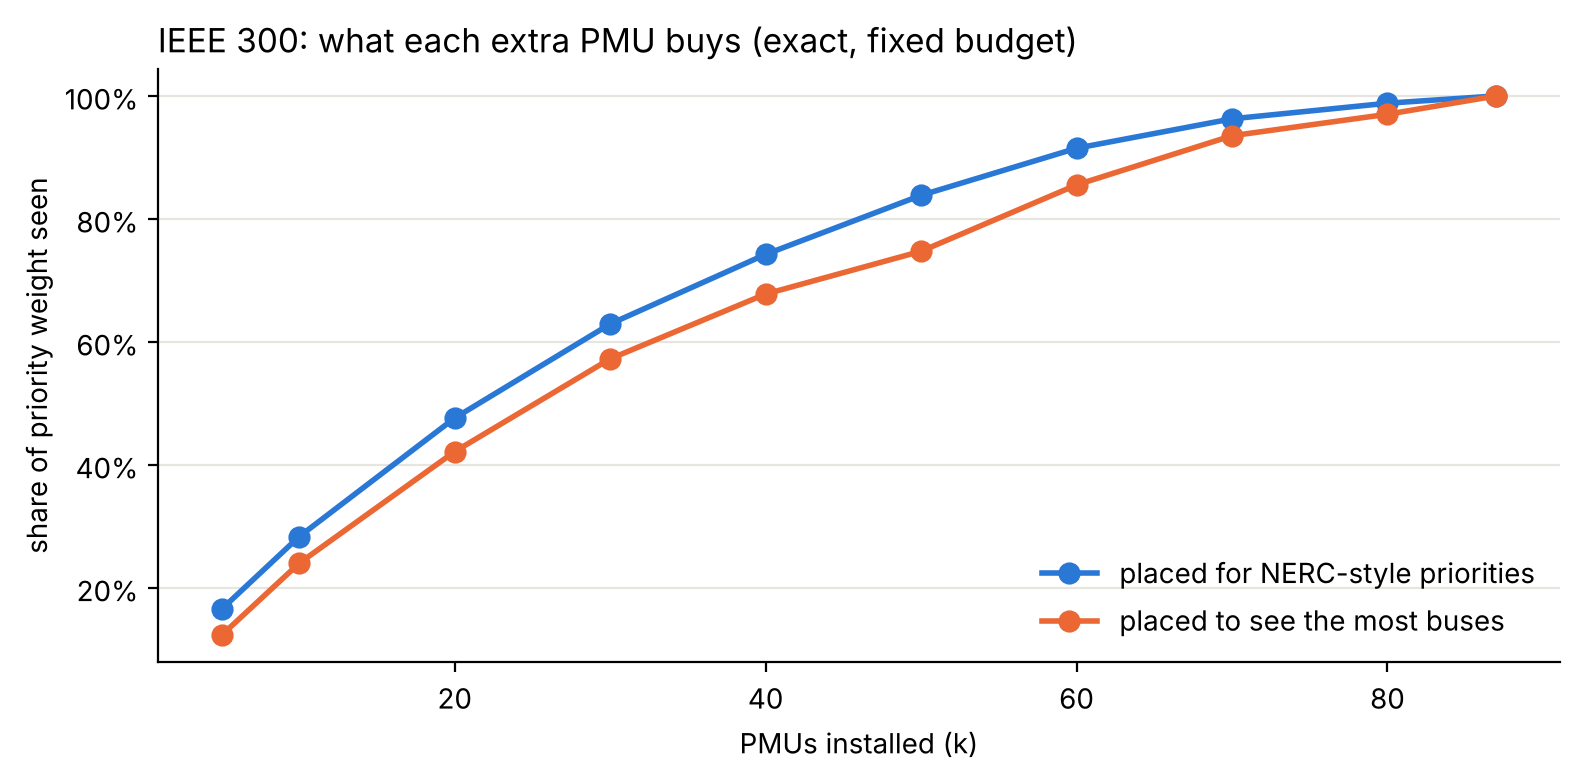

k=20: 48% of priority weight (123 of 300 buses seen)
k=30: 63% of priority weight (169 of 300 buses seen)
k=40: 74% of priority weight (199 of 300 buses seen)


In [20]:
s300 = json.load(open("results/ieee300_study.json"))
n1z_all = json.load(open("results/n1_zib.json"))
print("IEEE 300, exact classical answers")
for k in ["Greedy", "ILP", "ILP + zero-injection", "Greedy N-1", "N-1 ILP"]:
    print(f"  {k:22s} {s300[k]['count']:4d} PMUs  {s300[k]['ms']:7.0f} ms")
z = next(r for r in n1z_all if r["grid"] == "ieee300")
print(f"  {'N-1 + zero-injection':22s} {z['count']:4d} PMUs  {z['seconds'] * 1000:7.0f} ms   (scenario ILP; valid: {z['valid']})")
print()
print("N-1 with zero-injection on every grid:", {r["grid"]: r["count"] for r in n1z_all})

curve = s300["budget_curve"]
fig, ax = plt.subplots(figsize=(8, 4))
ks = [c["k"] for c in curve]
ax.plot(ks, [c["weighted_share"] for c in curve], "-o", color="#2a78d6", lw=2, ms=7, label="placed for NERC-style priorities")
ax.plot(ks, [c["weighted_share_of_unweighted"] for c in curve], "-o", color="#eb6834", lw=2, ms=7, label="placed to see the most buses")
ax.set_xlabel("PMUs installed (k)"); ax.set_ylabel("share of priority weight seen")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("IEEE 300: what each extra PMU buys (exact, fixed budget)", loc="left")
ax.legend(frameon=False, loc="lower right")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
ax.grid(axis="y", color="#e6e5e0"); plt.tight_layout(); plt.show()
for c in curve:
    if c["k"] in (20, 30, 40):
        print(f"k={c['k']}: {c['weighted_share']:.0%} of priority weight ({c['buses_seen_weighted']} of 300 buses seen)")

In [21]:
print(f"{'variant':6s} {'window':>6s} {'sampler':26s} {'start':>5s} {'final':>5s} {'optimum':>7s} {'windows':>7s}")
for r in s300["window_search"]:
    print(f"{r['variant']:6s} {r['window']:6d} {r['sampler']:26s} {r['start']:5d} {r['final']:5d} {r['optimum']:7d} {r['windows']:7d}")
print("two-qubit gates per QAOA layer for a 10-bus window:", s300.get("window_cx_per_layer"))

variant window sampler                    start final optimum windows
plain      10 QAOA, 2 layers                96    90      87     180
plain      10 random sampling               96    90      87     274
n1         10 QAOA, 2 layers               209   203     202     610
n1         10 random sampling              209   204     202     407
zib         8 QAOA, 2 layers                96    74      70     151
zib         8 random sampling               96    73      70     229
plain      14 QAOA, 2 layers                96    88      87     168
plain      14 random sampling               96    92      87     277
plain      14 exact window (classical)      96    88      87     172
two-qubit gates per QAOA layer for a 10-bus window: 258


**What the window search shows.** With 10-qubit windows, 200 random shots already cover a fifth of each
window's 1,024 placements, so QAOA and random sampling tie (96 to 90 PMUs). With 14-qubit windows, 200 shots
cover about 1% of 16,384 placements: random sampling stalls at 92, while QAOA reaches 88, the same as solving
each window exactly by brute force. N-1: QAOA 203, random 204 (optimum 202). Zero-injection with 8-qubit
windows: QAOA 74, random 73 (optimum 70). So QAOA helps when the window is too big to sample blindly, and it
never beats an exact window solve. Window search itself is local and stops a few PMUs short of the ILP,
which solves the whole grid in milliseconds. One more honest limit: a 10-bus window circuit is about 258
two-qubit gates per layer, so this ran on the simulator only.

## 10. Hardware (milestone 5)

We send five circuits, each with measured gates written out so the two-qubit count is the real one:

| circuit | what it answers | qubits | CX |
|---|---|---|---|
| `piece6_L1` | the README's required 6-bus piece | 6 | 26 |
| `ieee14_core_L3` | **the full IEEE 14 problem** (core after rules, plus sensors at 2 and 7) | 4 | 24 |
| `ieee300_core_L1` | **the full IEEE 300 problem** (core after rules, plus 85 fixed sensors) | 3 | 6 |
| `ieee14_core_grover` | full IEEE 14 by Grover, k = 2, two steps, no tuning | 4 | 84 |
| `ieee300_core_grover` | full IEEE 300 by Grover, k = 2, one step, no tuning | 3 | 24 |
| `ieee300_core_L2`, `_L3` | full IEEE 300, QAOA with 2 and 3 layers (second round) | 3 | 12, 18 |
| `ieee14_core_L4` | full IEEE 14, QAOA with 4 layers (second round) | 4 | 32 |

Order of runs: (1) IonQ's free simulator with the `forte-1` noise model, (2) Quantinuum's free H2 emulator,
(3) IonQ Forte, 200 shots each. Every submission is appended to `results/run_record.csv` with device, job ID,
shots, status and a label (simulator, emulator or QPU).

In [22]:
best_piece = pick(P6, 0.25, 1)["params"]
best_core = pick(R14, 1.0, 3)["params"]
HW = {
    "piece6_L1": dict(cands=piece["buses"], cons=grid_constraints(piece), params=best_piece, best=2, forced=[]),
    "ieee14_core_L3": dict(cands=red["cands"], cons=red["constraints"], params=best_core, best=4, forced=red["forced"]),
    "ieee300_core_L1": dict(cands=red300["cands"], cons=red300["constraints"], params=list(params300), best=87, forced=red300["forced"]),
    "ieee14_core_grover": dict(cands=red["cands"], cons=red["constraints"], params=[], best=4, forced=red["forced"], grover=(2, 2)),
    "ieee300_core_grover": dict(cands=red300["cands"], cons=red300["constraints"], params=[], best=87, forced=red300["forced"], grover=(2, 1)),
}
for name, h in HW.items():
    if "grover" in h:
        try:
            qc = grover_circuit(h["cands"], h["cons"], *h["grover"])
        except Exception as e:  # older Qiskit without boolean-oracle synthesis: use the saved circuit
            print(f"{name}: building the oracle failed ({e}); loading hardware/{name}.qasm")
            qc = qasm2.load(f"hardware/{name}.qasm", custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)
    else:
        qc = qaoa_circuit_cover(h["cands"], h["cons"], h["params"])
    ncx, t = cx_count(qc)
    h["qc"] = t
    if not (IN_QBRAID and "grover" in h and Path(f"hardware/{name}.qasm").exists()):
        Path(f"hardware/{name}.qasm").write_text(qasm2.dumps(t))
    print(f"{name:20s} qubits {t.num_qubits}  CX {ncx:3d}  qubit i = bus {h['cands']}")
json.dump({k: {"cands": v["cands"], "params": [float(x) for x in v["params"]], "forced": v["forced"]} for k, v in HW.items()},
          open("hardware/circuits.json", "w"), indent=1)

piece6_L1            qubits 6  CX  26  qubit i = bus [2, 3, 5, 6, 10, 11]
ieee14_core_L3       qubits 4  CX  24  qubit i = bus [6, 9, 10, 13]
ieee300_core_L1      qubits 3  CX   6  qubit i = bus [243, 245, 246]
ieee14_core_grover   qubits 4  CX  84  qubit i = bus [6, 9, 10, 13]


ieee300_core_grover  qubits 3  CX  24  qubit i = bus [243, 245, 246]


In [23]:
# ---- Cloud runs through qBraid. Set RUN_CLOUD = True in qBraid Lab. ----
RUN_CLOUD = False
DEVICES = [
    ("ionq:ionq:sim:simulator", {"noise_model": "forte-1"}, "simulator (forte-1 noise)"),
    ("quantinuum:quantinuum:sim:h2-emulator", None, "emulator"),
    # ("ionq:ionq:qpu:forte-1", None, "QPU"),          # uncomment when tuned; 200 shots max
    # ("aws:ionq:qpu:forte-1", None, "QPU via AWS"),   # if the line above shows unavailable
]
SHOTS = 200
record = Path("results/run_record.csv")
if not record.exists():
    record.write_text("time,circuit,device,label,job_id,shots,status\n")

jobs = {}
if RUN_CLOUD and IN_QBRAID:
    import warnings
    from qbraid.runtime import QbraidProvider
    warnings.filterwarnings("ignore", message="Circuit contains measurement gates")
    provider = QbraidProvider()
    for dev_id, opts, label in DEVICES:
        device = provider.get_device(dev_id)
        for name, h in HW.items():
            try:
                job = device.run(h["qc"], shots=SHOTS, **({"runtime_options": opts} if opts else {}))
                jobs[(name, dev_id)] = job
                status = str(job.status())
                jid = job.id
            except Exception as e:  # keep failures in the record too
                status, jid = f"FAILED: {e}".replace(",", ";")[:120], ""
            with record.open("a") as f:
                f.write(f"{time.strftime('%Y-%m-%d %H:%M')},{name},{dev_id},{label},{jid},{SHOTS},{status}\n")
            print(f"{name:16s} {dev_id:40s} job {jid} {status}")
else:
    print("Cloud runs are off here. In qBraid Lab set RUN_CLOUD = True.")

Cloud runs are off here. In qBraid Lab set RUN_CLOUD = True.


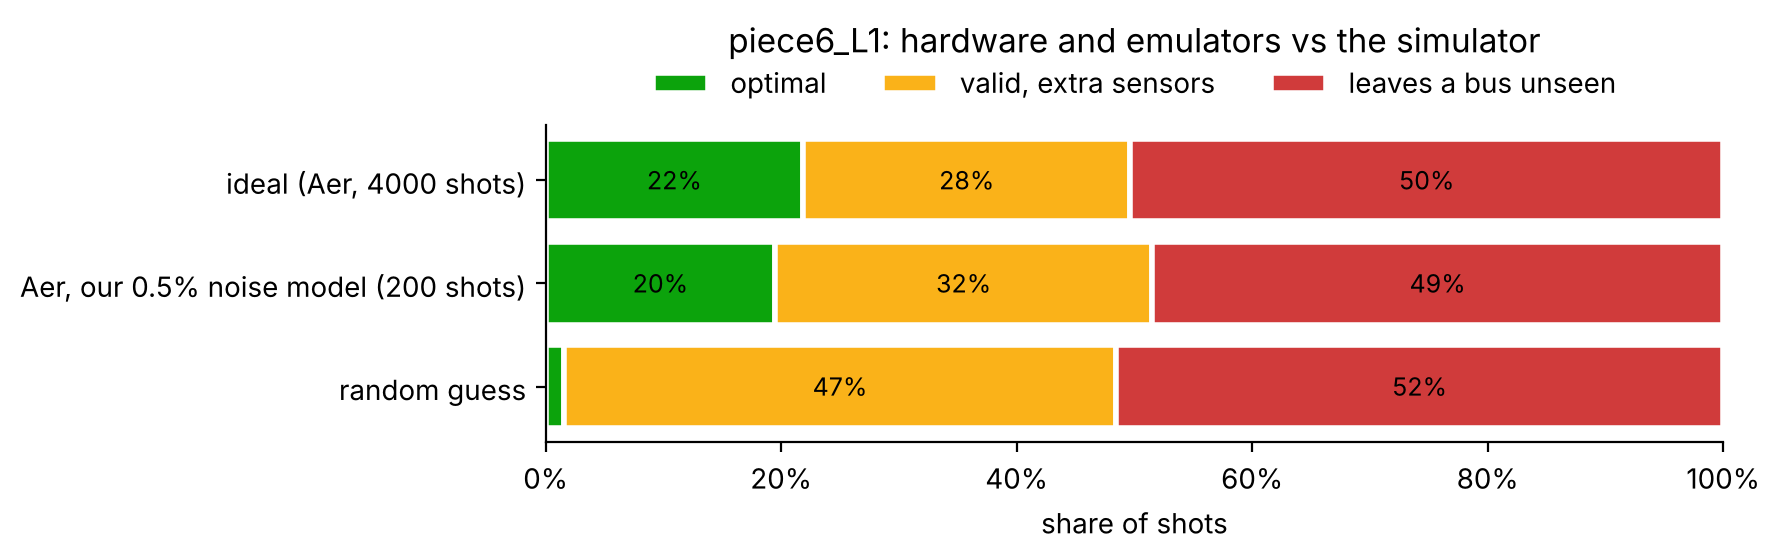

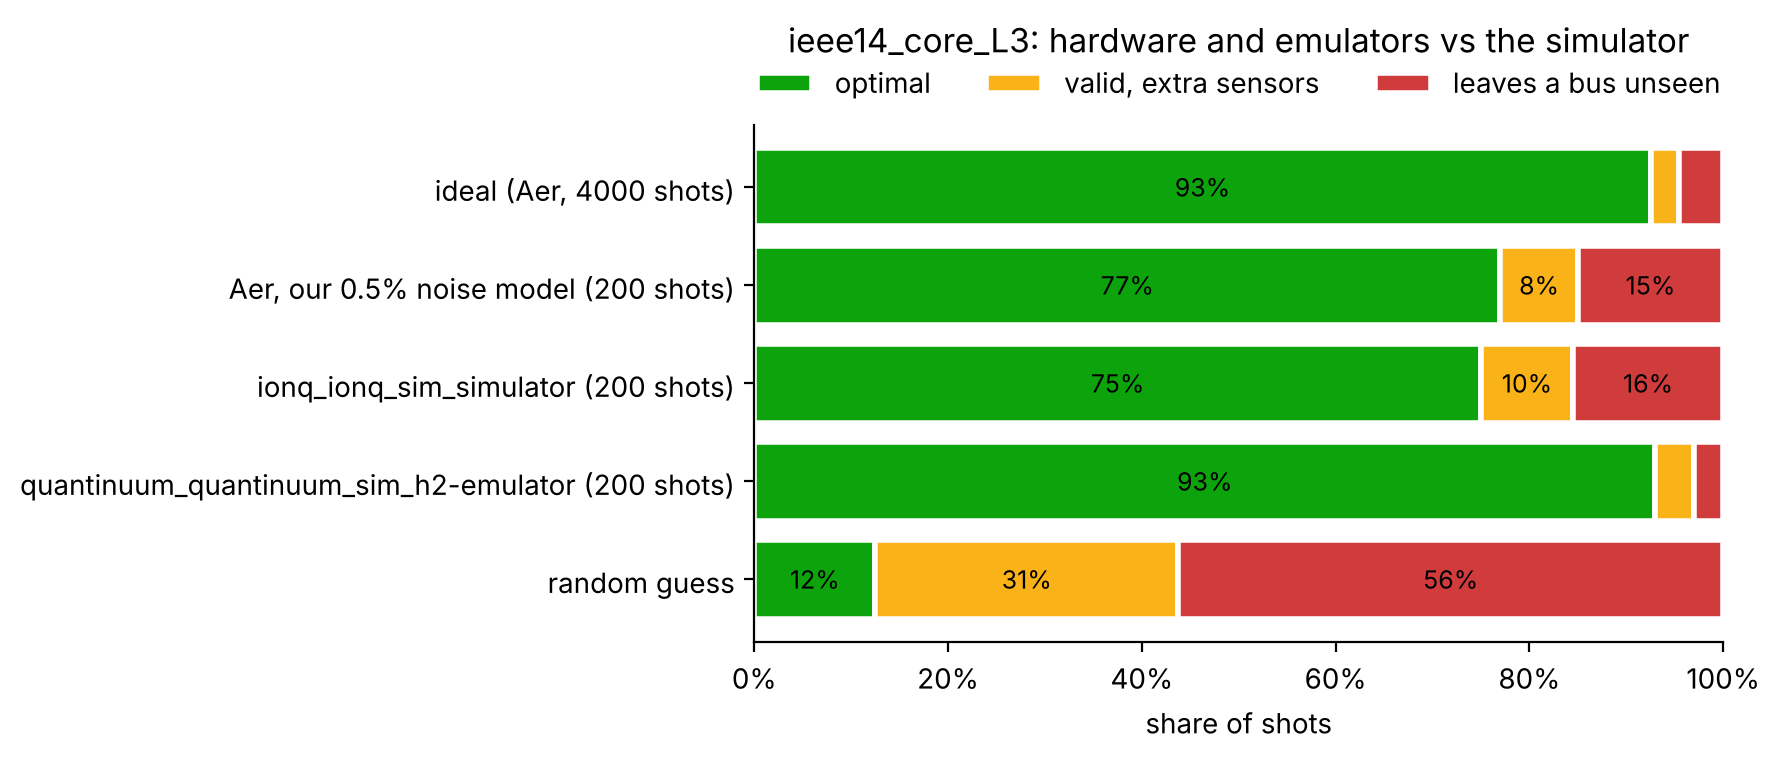

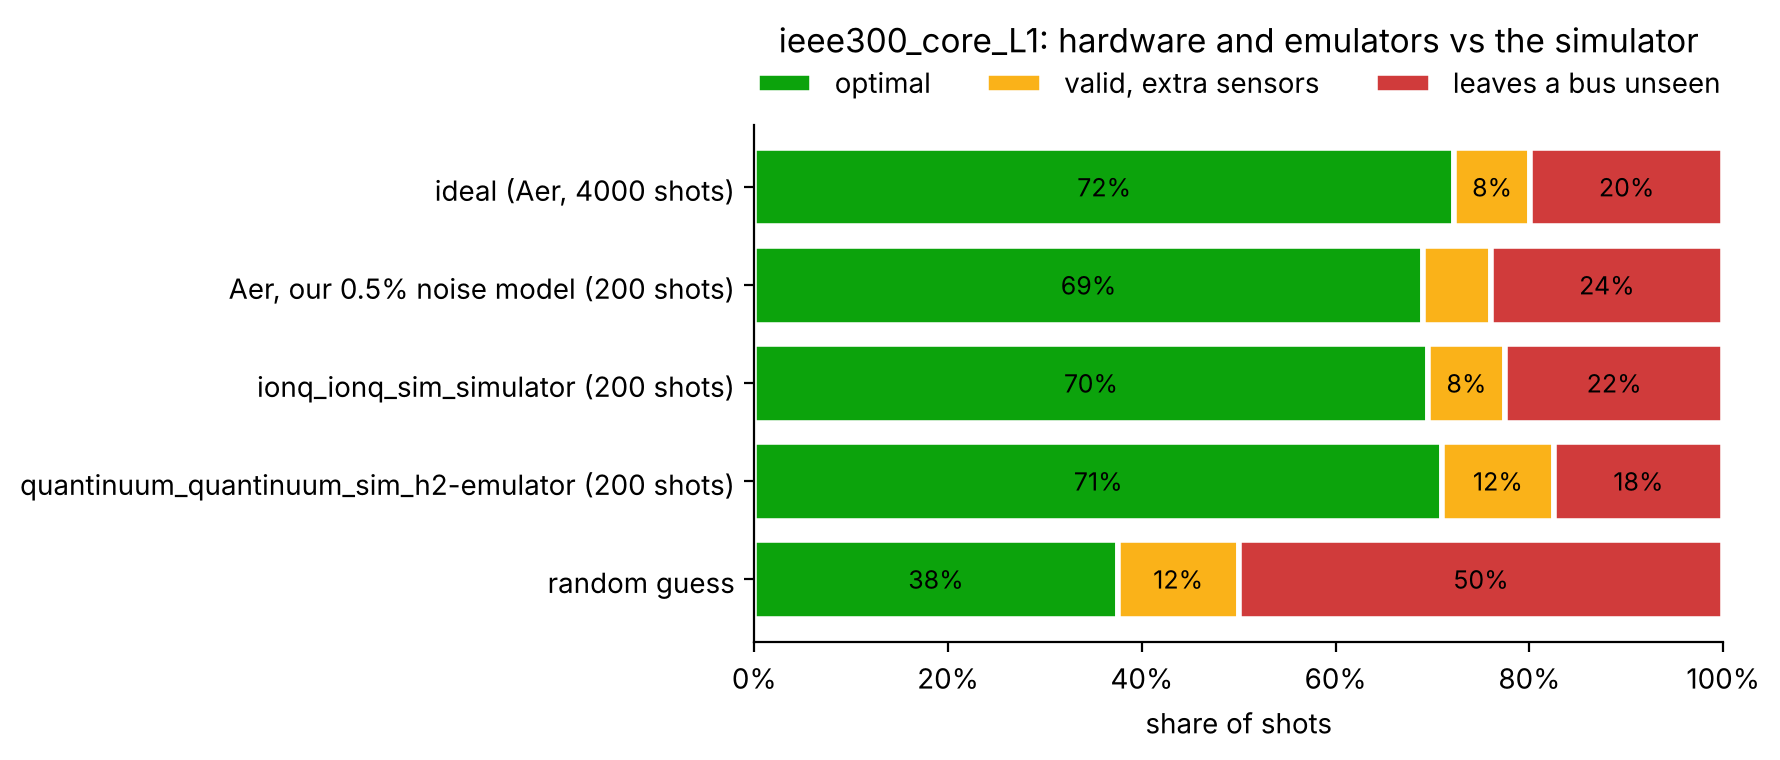

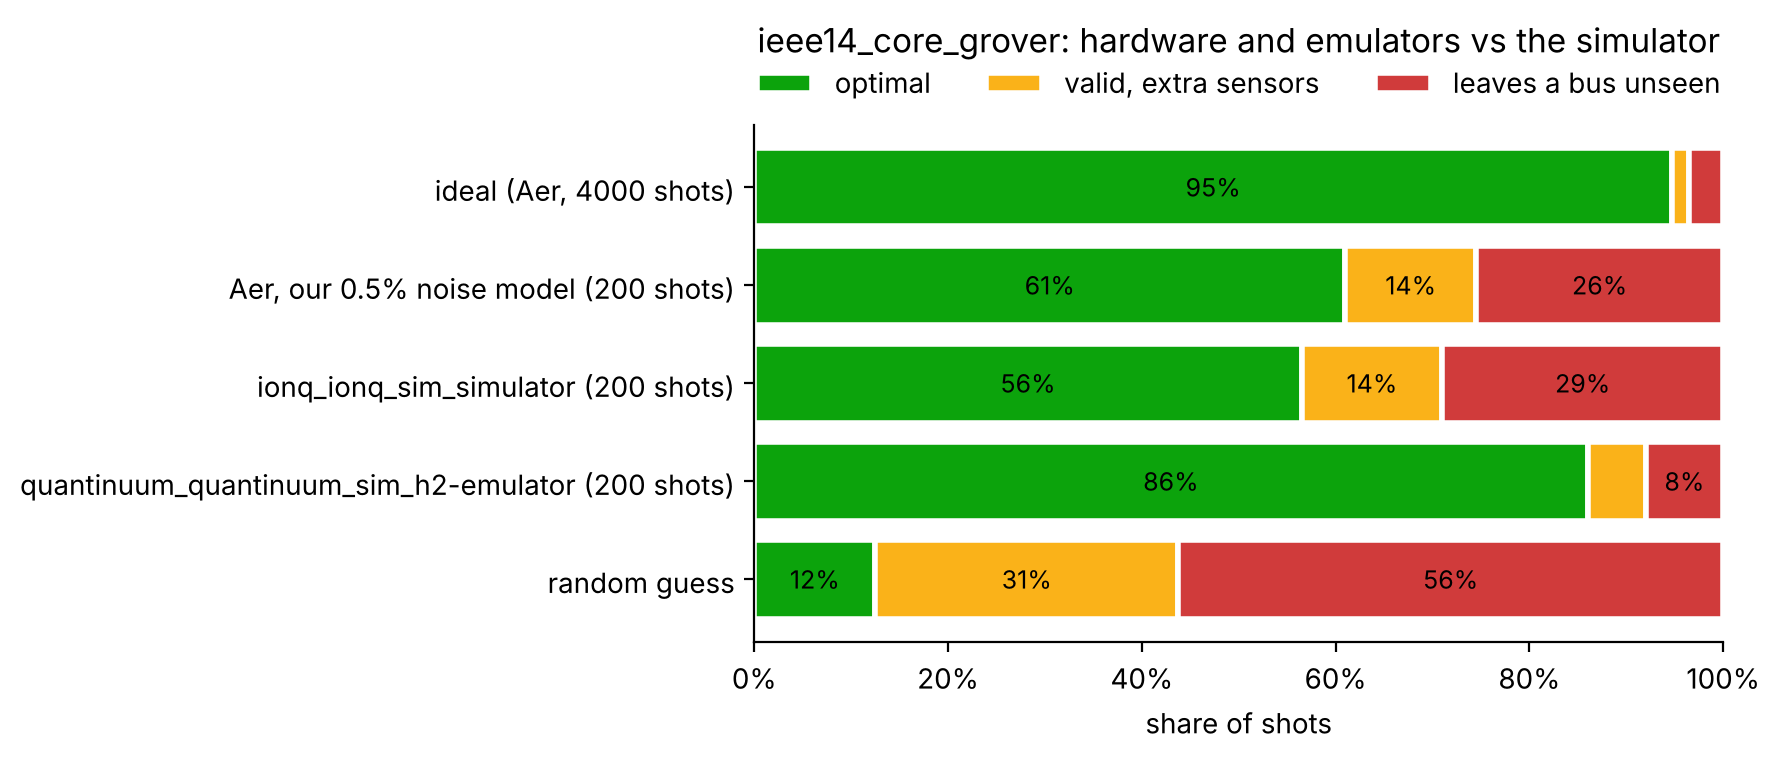

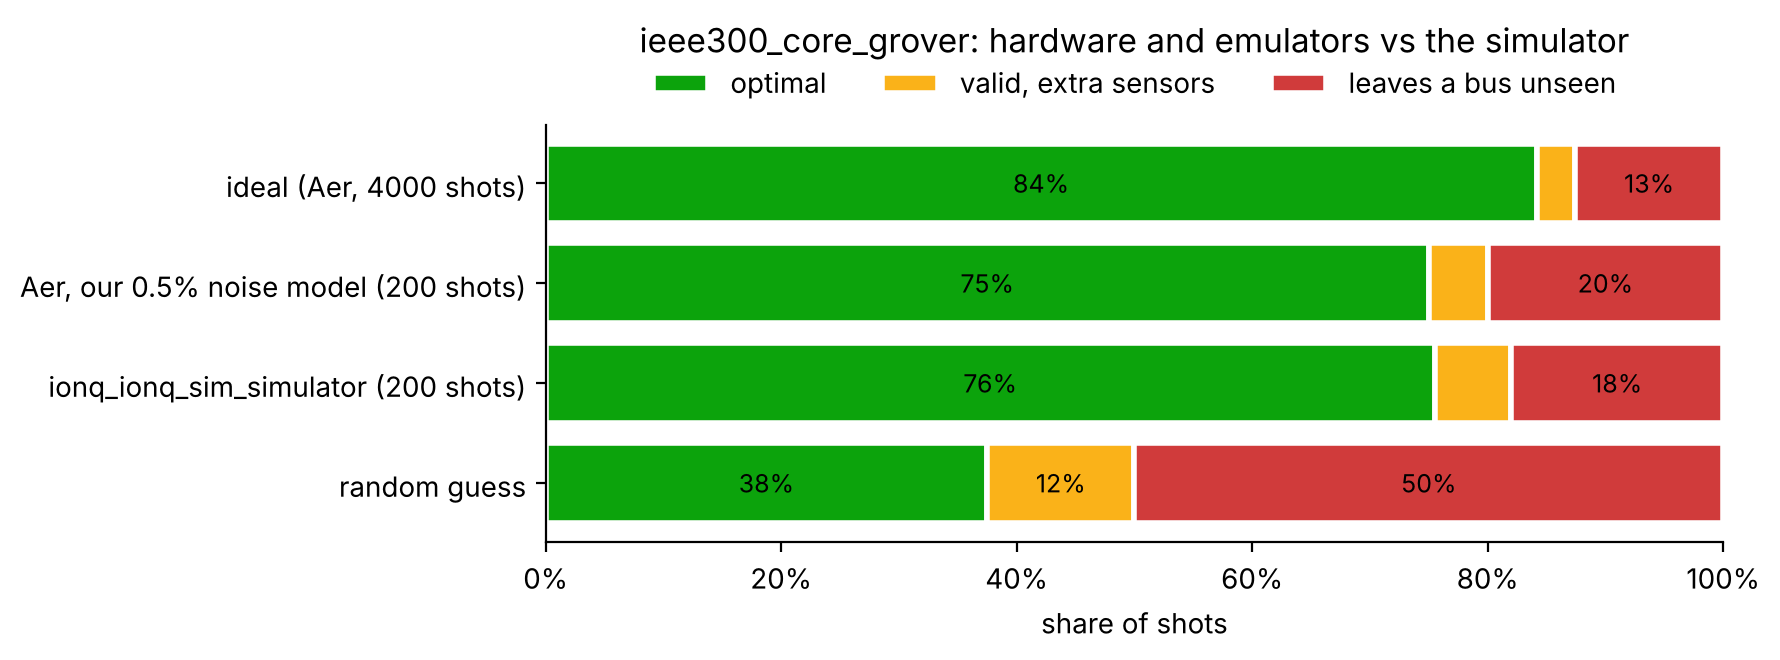

In [24]:
# ---- Collect results (rerun until jobs finish). Counts are also saved to results/counts_<circuit>_<device>.json ----
def to_probs(counts, n):
    pr = np.zeros(2 ** n)
    for k, c in counts.items():
        pr[int(k.replace(" ", ""), 2)] += c
    return pr / pr.sum()

for (name, dev_id), job in jobs.items():
    try:
        counts = job.result().data.get_counts()
        Path(f"results/counts_{name}_{dev_id.replace(':', '_')}.json").write_text(json.dumps(counts))
        print(name, dev_id, "done")
    except Exception as e:
        print(name, dev_id, "not ready:", e)

# Our own noisy-simulator baseline (0.5% two-qubit error), so there is always something to compare against
from noise_study import noise_model
noisy = AerSimulator(noise_model=noise_model(0.005), seed_simulator=3)
for name, h in HW.items():
    n = len(h["cands"])
    rows = {"ideal (Aer, 4000 shots)": shares(h["cands"], h["cons"], to_probs(AerSimulator().run(h["qc"], shots=4000).result().get_counts(), n), h["best"], len(h["forced"]))}
    rows["Aer, our 0.5% noise model (200 shots)"] = shares(h["cands"], h["cons"], to_probs(noisy.run(h["qc"], shots=200).result().get_counts(), n), h["best"], len(h["forced"]))
    for f in sorted(Path("results").glob(f"counts_{name}_*.json")):
        dev = f.stem.replace(f"counts_{name}_", "")
        c = json.loads(f.read_text())
        rows[f"{dev} ({sum(c.values())} shots)"] = shares(h["cands"], h["cons"], to_probs(c, n), h["best"], len(h["forced"]))
    rows["random guess"] = shares(h["cands"], h["cons"], np.full(2 ** n, 2.0 ** -n), h["best"], len(h["forced"]))
    plot_outcomes(rows, f"{name}: hardware and emulators vs the simulator")

### Our cloud runs (Saturday 14 November, 200 shots each)

Eleven jobs through qBraid: all six circuits on IonQ's simulator with the `forte-1` noise model, and the five
small ones on Quantinuum's H2 emulator. Both are simulators of noisy hardware, so they are labeled that way;
the Forte QPU showed as unavailable on qBraid when we ran. Job IDs are in `results/run_record.csv`.

circuit                device                        optimal   extra  unseen  job
piece6_L1              simulator (forte-1 noise)       19.0%   27.0%   54.0%  6af86ab6c8f5265fb3f1b044
ieee14_core_L3         simulator (forte-1 noise)       75.0%    9.5%   15.5%  6af86ab7c8f5265fb3f1b048
ieee14_core_grover     simulator (forte-1 noise)       56.5%   14.5%   29.0%  6af86ab8c8f5265fb3f1b04c
ieee300_core_L1        simulator (forte-1 noise)       69.5%    8.0%   22.5%  6af86ab9c8f5265fb3f1b050
ieee300_core_grover    simulator (forte-1 noise)       75.5%    6.5%   18.0%  6af86abac8f5265fb3f1b054
ieee14_full_L1         simulator (forte-1 noise)        0.5%   37.5%   62.0%  6af86abcc8f5265fb3f1b059
piece6_L1              emulator                        18.0%   34.0%   48.0%  6af86c16c8f5265fb3f1b0c5
ieee14_core_L3         emulator                        93.0%    4.0%    3.0%  6af86c17c8f5265fb3f1b0c8
ieee14_core_grover     emulator                        86.0%    6.0%    8.0%  6af86c18c8f5265f

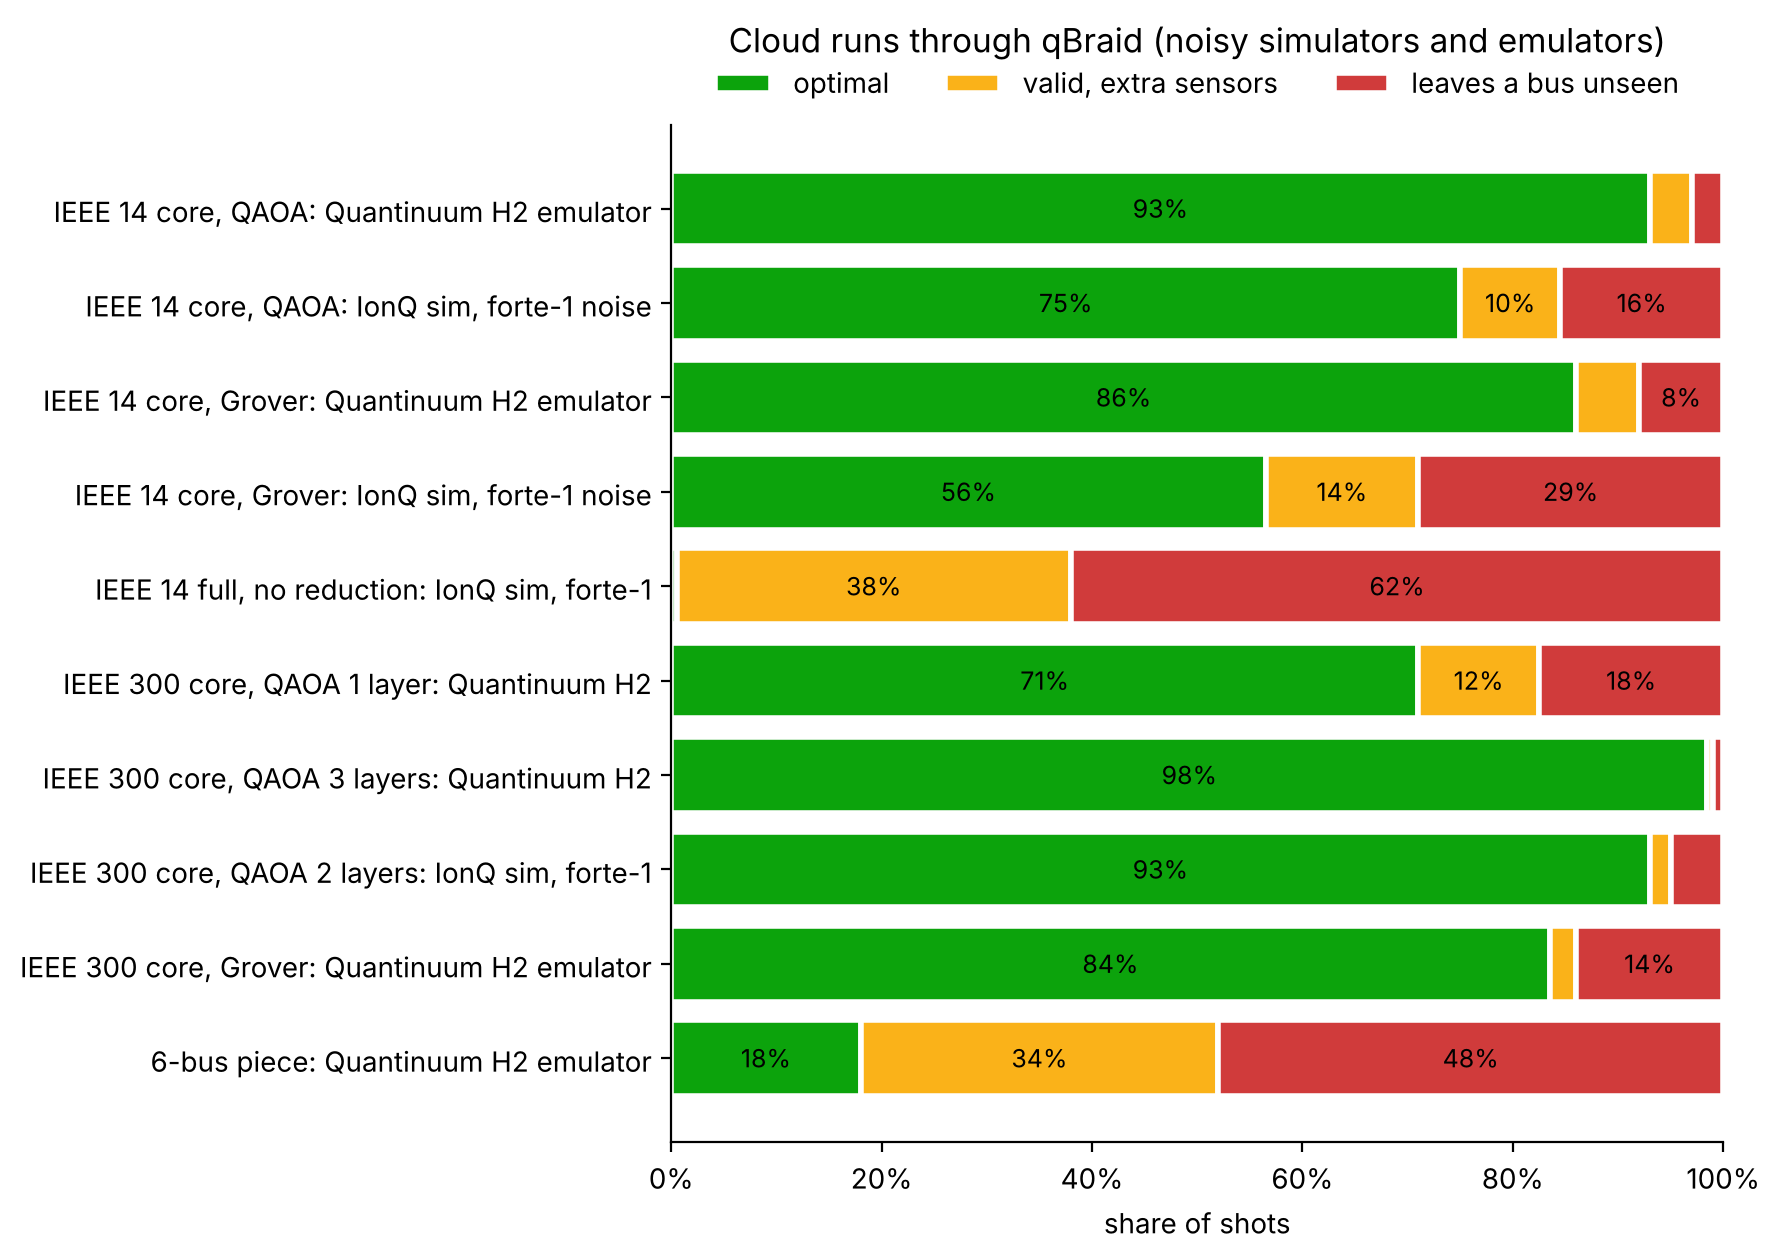

In [25]:
hw = json.load(open("results/hardware_summary.json"))
print(f"{'circuit':22s} {'device':28s} {'optimal':>8s} {'extra':>7s} {'unseen':>7s}  job")
for key, v in hw.items():
    name, dev = key.split("|")
    print(f"{name:22s} {v['label']:28s} {v['optimal']:8.1%} {v['valid, extra sensors']:7.1%} {v['leaves a bus unseen']:7.1%}  {v['job_id'].split('qjob-')[-1]}")
pick_hw = lambda n, d: next(v for k, v in hw.items() if k.startswith(n + "|") and d in k)
plot_outcomes({
    "IEEE 14 core, QAOA: Quantinuum H2 emulator": pick_hw("ieee14_core_L3", "quantinuum"),
    "IEEE 14 core, QAOA: IonQ sim, forte-1 noise": pick_hw("ieee14_core_L3", "ionq"),
    "IEEE 14 core, Grover: Quantinuum H2 emulator": pick_hw("ieee14_core_grover", "quantinuum"),
    "IEEE 14 core, Grover: IonQ sim, forte-1 noise": pick_hw("ieee14_core_grover", "ionq"),
    "IEEE 14 full, no reduction: IonQ sim, forte-1": pick_hw("ieee14_full_L1", "ionq"),
    "IEEE 300 core, QAOA 1 layer: Quantinuum H2": pick_hw("ieee300_core_L1", "quantinuum"),
    "IEEE 300 core, QAOA 3 layers: Quantinuum H2": pick_hw("ieee300_core_L3", "quantinuum"),
    "IEEE 300 core, QAOA 2 layers: IonQ sim, forte-1": pick_hw("ieee300_core_L2", "ionq"),
    "IEEE 300 core, Grover: Quantinuum H2 emulator": pick_hw("ieee300_core_grover", "quantinuum"),
    "6-bus piece: Quantinuum H2 emulator": pick_hw("piece6_L1", "quantinuum"),
}, "Cloud runs through qBraid (noisy simulators and emulators)")

The reduction is what makes the difference on noisy machines. The full 14-bus circuit, 336 two-qubit gates,
returned an optimal placement in 1 of 200 shots on IonQ's Forte-noise simulator. The reduced core of the same
problem, 24 gates, returned one in 75% of shots there and 93% on Quantinuum's H2 emulator. The two answers it
finds are sensors at {2, 7, 6, 9} and {2, 7, 10, 13}, both 4 PMUs and both optimal.

**Second round: deeper QAOA on the IEEE 300 core.** Our first 300-bus circuit had one QAOA layer, which tops
out at 72% even with no noise, so it lost to Grover (84%). The core is only 3 qubits and each layer costs 6
two-qubit gates, so we tuned 2 and 3 layers (ideal 95.5% and 99.8%) and reran. Quantinuum H2 emulator: 71%
with 1 layer, 92.5% with 2, **98.5% with 3** (18 CX). IonQ's Forte-noise simulator: 70%, 93%, 89%; there 2
layers did best, because its noise model charges more per gate. A 4th layer on the IEEE 14 core did not help
(87% vs 93% on Quantinuum, 81% vs 75% on IonQ), so 3 layers stays our IEEE 14 choice for Quantinuum.

## 10b. Grid scale: 25,000 and 70,000 buses

The challenge data stops at IEEE 300, so we pulled two public synthetic grids from MATPOWER, built by
Texas A&M to look like real US networks: **ACTIVSg25k** and **ACTIVSg70k**. The 70k grid is modeled on the
US Eastern Interconnection, which TVA's own grid is part of. They are synthetic, not TVA's real network.
`matpower_import.py` converts them (zero-injection = no load, no shunt, no generator); `big_grid.py` has
sparse versions of greedy, the ILPs and the reduction; `big_quantum.py` runs QAOA on every piece the
reduction leaves. The converted grids are in `data_big/`.

In [26]:
for name in ["case_ACTIVSg25k", "case_ACTIVSg70k"]:
    d = json.load(open(f"results/big_{name}.json"))["out"]
    q = json.load(open(f"results/big_quantum_{name}.json"))
    r = d["reduction"]
    print(f"{name}: {d['buses']:,} buses, {d['lines']:,} lines")
    print(f"  greedy {d['greedy'][0]:,} PMUs ({d['greedy'][1]} s) | exact ILP {d['ilp'][0]:,} ({d['ilp'][1]} s) | N-1 ILP {d['n1'][0]:,} ({d['n1'][1]} s)")
    if "ilp_zib" in d:
        print(f"  zero-injection ILP: {d['ilp_zib'][0]:,} PMUs, valid, but stopped at the {d['ilp_zib'][1]:.0f} s limit with a {d['ilp_zib'][3]:.0%} gap (not proven minimal)")
    print(f"  reduction: {r['forced']:,} PMUs fixed in {r['seconds']} s; {r['qubits_left']} qubits left in {r['pieces']} pieces, largest {r['largest_pieces'][:5]}")
    s = q["summary"]
    worst = min(q["pieces"], key=lambda p: p["p_optimal_per_shot"])
    print(f"  QAOA on every piece: total {s['total_pmus']:,} PMUs, valid {s['valid']}, all pieces optimal {s['all_pieces_optimal']}; "
          f"hardest piece {worst['qubits']} qubits, {worst['p_optimal_per_shot']:.1%} of shots optimal (random guessing: {worst['optimal_states']} optimal of {2 ** worst['qubits']:,} placements)")
    print()

case_ACTIVSg25k: 25,000 buses, 30,110 lines
  greedy 8,399 PMUs (0.09 s) | exact ILP 7,871 (0.21 s) | N-1 ILP 19,428 (0.24 s)
  zero-injection ILP: 5,529 PMUs, valid, but stopped at the 1201 s limit with a 48% gap (not proven minimal)
  reduction: 7,857 PMUs fixed in 0.2 s; 24 qubits left in 6 pieces, largest [5, 5, 4, 4, 3]
  QAOA on every piece: total 7,871 PMUs, valid True, all pieces optimal True; hardest piece 5 qubits, 89.0% of shots optimal (random guessing: 5 optimal of 32 placements)

case_ACTIVSg70k: 70,000 buses, 83,318 lines
  greedy 24,119 PMUs (0.34 s) | exact ILP 22,777 (0.72 s) | N-1 ILP 53,612 (0.88 s)
  reduction: 22,676 PMUs fixed in 0.5 s; 191 qubits left in 38 pieces, largest [19, 13, 10, 8, 7]
  QAOA on every piece: total 22,777 PMUs, valid True, all pieces optimal True; hardest piece 19 qubits, 2.0% of shots optimal (random guessing: 11 optimal of 524,288 placements)



At 70,000 buses the exact ILP still takes under a second, and the exact rules do almost all the work:
22,676 of 22,777 sensors are fixed before any qubit is used. What is left splits into 38 independent pieces,
the largest 19 qubits. QAOA found the optimum of every piece in simulation, so the assembled answer equals
the ILP's 22,777. Greedy needs 1,342 more, which at DOE's cost is about \$54M to \$242M. Again, that saving
belongs to the exact method, not to quantum.

### The team's 55,000-bus synthetic grid

`ilp_55000.ipynb` (a teammate's notebook) builds a random 55,000-bus grid: buses at random points, a spanning
tree over near neighbors, plus extra short lines, 74,249 lines in all. `synth55k.py` rebuilds exactly the
same grid (same generator and seed). It is much less structured than the Texas A&M grids, so the rules leave
far more for qubits: 7,020 qubits in 498 pieces, the largest 172. QAOA (simulated) took every piece up to 16
qubits; the ILP took the rest.

In [27]:
d = json.load(open("results/big_synthetic_55000-bus.json"))["out"]
q = json.load(open("results/big_quantum_synthetic_55000-bus.json"))["summary"]
print(f"greedy {d['greedy'][0]:,} | exact ILP {d['ilp'][0]:,} ({d['ilp'][1]} s) | N-1 ILP {d['n1'][0]:,} ({d['n1'][1]} s)")
print(f"rules fix {q['forced']:,}; {q['pieces']} pieces, {q['qubits']:,} qubits")
print(f"QAOA solved {q['pieces_by_qaoa']} pieces (<= 16 qubits) choosing {q['pmus_chosen_by_qaoa']:,} PMUs, "
      f"{q['qaoa_pieces_optimal']} of them optimally; the ILP solved the other {q['pieces'] - q['pieces_by_qaoa']} pieces ({q['pmus_from_ilp_pieces']:,} PMUs)")
print(f"hybrid total {q['total_pmus']:,} PMUs, valid {q['valid']}, vs exact {d['ilp'][0]:,}")

greedy 17,767 | exact ILP 16,119 (6.54 s) | N-1 ILP 33,972 (4.42 s)
rules fix 13,216; 498 pieces, 7,020 qubits
QAOA solved 372 pieces (<= 16 qubits) choosing 1,061 PMUs, 370 of them optimally; the ILP solved the other 126 pieces (1,844 PMUs)
hybrid total 16,121 PMUs, valid True, vs exact 16,119


### Parameter sweep on qBraid (Saturday)

21 circuits, each tuned on the exact statevector, sent to IonQ's simulator with the `forte-1` noise model and
to Quantinuum's H2 emulator: QAOA layers, the penalty weight P, Grover step counts, two QUBO forms (an
unbalanced penalty with only two-qubit terms, and slack qubits), and the stretch goals written as circuits
(N-1 core and the fixed budget, compiled term by term). Zero-injection as a circuit needs 3,854 two-qubit
gates, so it stayed in simulation. `python sweep_build.py` rebuilds the circuits.

In [28]:
sw = json.load(open("results/sweep_results.json"))
print(f"{'circuit':26s} {'qubits':>6s} {'CX':>5s} {'ideal':>6s} {'IonQ sim':>9s} {'H2 emu':>7s}")
for name, r in sw.items():
    h2 = f"{r['quantinuum_opt']:.0%}" if "quantinuum_opt" in r else "queued"
    print(f"{name:26s} {r['qubits']:6d} {r['cx']:5d} {r['ideal']:6.0%} {r['ionq_opt']:9.1%} {h2:>7s}")

circuit                    qubits    CX  ideal  IonQ sim  H2 emu
ieee14_core_L1                  4     8    33%     32.0%     35%
ieee14_core_L2                  4    16    64%     61.0%     62%
ieee14_core_L5                  4    40    98%     80.0%  queued
ieee14_core_L2_P1p5             4    16    78%     69.5%  queued
ieee14_core_L2_P3p0             4    16    92%     81.0%  queued
ieee14_core_L2_P5p0             4    16    85%     80.5%  queued
ieee14_core_grover_1step        4    42    78%     62.5%  queued
ieee14_core_grover_3step        4   126    33%     24.0%  queued
ieee300_core_L4                 3    24   100%     93.5%  queued
ieee300_core_L5                 3    30   100%     85.5%  queued
piece6_L2                       6    52    23%     19.0%  queued
piece6_L3                       6    78    25%     18.5%  queued
piece6_qubo_L1                  6    18    13%     11.0%  queued
piece6_qubo_L2                  6    36    21%     16.0%  queued
ieee14_full_qubo_L1      

What the sweep says: tuning the penalty beats adding layers (P = 3 with 2 layers reaches 81% on the noisy IonQ
model with 16 two-qubit gates, as good as 5 layers with 40). The IEEE 300 core with 4 layers reaches 93.5%.
Both QUBO forms do much worse than the direct cost: covering constraints need slack qubits or approximate
penalties, and both waste probability. The N-1 and fixed-budget circuits are hundreds of gates deep and come
back near zero, so those stretch goals stay classical (or simulated) for now.

## 11. What it means for TVA

**The placement.** On IEEE 14, 4 PMUs at buses {2, 6, 7, 9} see every bus. With the zero-injection rule at
bus 7, 3 PMUs at {2, 6, 9} do. To survive any one PMU failure: 9 PMUs, or 7 with zero-injection.

**The money.** DOE (2014) put installed cost at \$40,000 to \$180,000 per PMU. Greedy versus optimal differs by 1 PMU on
IEEE 14, 4 on IEEE 118 and 9 on IEEE 300, so an exact method is worth \$40k to \$1.6M on these grids. That
value comes from the **integer program, not from quantum**. The quantum part adds no savings today.

**Where quantum stands, with our numbers.**
* The ILP solves every grid here in under 60 ms. QAOA on the full 14-bus grid needs 1,300+ two-qubit gates
  for a 16% optimal rate, and under our noise model its 1-layer version drops to 1.5% at Forte-like error.
* After exact classical rules, the leftover core is small enough for today's hardware (24 CX for all of
  IEEE 14) and QAOA then finds the optimum most of the time. That is a real, honest hybrid workflow, but
  the classical rules are doing most of the work.
* Tuning without the full cost table took 15,000 to 45,000 shots. On hardware, that cost dominates.
* Grover search on the core gets the same answer with no tuning at all, at the price of more gates.
* For quantum to matter, the problem has to be one the rules and the ILP cannot crack: a much larger
  or messier objective. N-1 with zero-injection is the first sign of that here: 0.3 s on IEEE 30 but about
  14 minutes on IEEE 300 for our exact solver. That would need hardware with far more qubits and lower error.